<a href="https://colab.research.google.com/github/SoHaila338/Image-classification-using-deep-learning/blob/main/Retinal_CAD_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SECTION 1 - Environment setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

%pip install -q openpyxl accelerate huggingface_hub joblib scikit-image
%pip install -q -U "transformers>=4.50.0"


In [ ]:
import os, sys, json, math, time, random, hashlib, warnings, shutil, re, copy
from dataclasses import dataclass, asdict, field
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Any
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_PROJECT_DIR = "/content/drive/MyDrive/retinal_cad"
else:
    DRIVE_PROJECT_DIR = str(Path.cwd() / "retinal_cad")   # local fallback
print("Colab:", IN_COLAB, "| project dir:", DRIVE_PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | project dir: /content/drive/MyDrive/retinal_cad


In [ ]:

# ====================== GOOGLE DRIVE DATA PATHS ======================

from pathlib import Path

DATASET_ROOT = "/content/drive/MyDrive/Retinal_CAD/dataset"

BASELINE_DIR = (
    f"{DATASET_ROOT}/baseline fundus images"
)

FOLLOWUP_DIR = (
    f"{DATASET_ROOT}/2 year follow-up fundus images"
)

EXCEL_PATH = (
    f"{DATASET_ROOT}/Organized_Data of Patients.xlsx"
)

MANIFEST_PATH = (
    f"{DATASET_ROOT}/corrected_manifest.csv"
)

# ====================== OUTPUT PATHS ======================

DRIVE_PROJECT_DIR = "/content/drive/MyDrive/Retinal_CAD"

OUTPUT_DIR = f"{DRIVE_PROJECT_DIR}/outputs"

CHECKPOINT_DIR = f"{OUTPUT_DIR}/checkpoints"
REPORTS_DIR = f"{OUTPUT_DIR}/reports"
PROCESSED_DIR = f"{OUTPUT_DIR}/processed"
FIGURES_DIR = f"{OUTPUT_DIR}/figures"
SPLITS_DIR = f"{OUTPUT_DIR}/splits"
RESULTS_DIR = f"{OUTPUT_DIR}/results"

LOCAL_CACHE = "/content/local_cache"

# No Hugging Face download needed
DOWNLOAD_DATASET = False

HF_DATASET_REPO = None
HF_TOKEN = None



CFG = dict(
    seed=42,

    # Training
    batch_size=8,
    num_workers=2,
    epochs=30,

    # Transfer Learning
    warmup_epochs=3,
    unfreeze="layer3_4",

    # Optimizer
    lr_head=2e-4,
    lr_backbone=1e-5,
    weight_decay=1e-4,

    # Regularization
    dropout=0.4,
    label_smoothing=0.03,
    grad_clip=1.0,

    # Architecture
    embed_dim=256,
    use_signed_diff=True,

    # Training stability
    patience=6,
    use_amp=True,

    # Dataset split
    val_frac=0.10,
    test_frac=0.10,

    # Longitudinal learning
    use_registered_followup=True,

    # Augmentation
    allow_hflip=False,
    aug_rot_deg=5.0,
    aug_scale=0.03,
    aug_shift_frac=0.02,

    # Fresh training
    retrain=True,
)

RUN_EXPERIMENTS = ["E3"]
MIN_MANIFEST_QUALITY = None

In [ ]:
class NpEncoder(json.JSONEncoder):
    def default(self, o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        if isinstance(o, Path): return str(o)
        return super().default(o)

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, cls=NpEncoder, ensure_ascii=False)

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(CFG["seed"])

for d in [OUTPUT_DIR, CHECKPOINT_DIR, REPORTS_DIR, PROCESSED_DIR, FIGURES_DIR, SPLITS_DIR, RESULTS_DIR]:
    Path(d).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory/1e9:.1f} GB | capability {p.major}.{p.minor}")
else:
    print("WARNING: no GPU. Enable Runtime > Change runtime type > GPU. CPU training is impractical and MedGemma needs a GPU.")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| cv2", cv2.__version__)

GPU: Tesla T4 | 15.6 GB | capability 7.5
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | cv2 4.14.0


## SECTION 2 - Dataset inspection and validation
We first locate/download the dataset, then **inspect what is really there** (directories, CSV columns, Excel sheets/columns, grades, image paths) before any modelling.

In [ ]:

IMG_EXTS = {
    ".jpg", ".jpeg", ".png",
    ".tif", ".tiff", ".bmp"
}

def ensure_dataset():

    required_paths = {
        "Dataset root": DATASET_ROOT,
        "Baseline images": BASELINE_DIR,
        "Follow-up images": FOLLOWUP_DIR,
        "Excel file": EXCEL_PATH,
        "Manifest file": MANIFEST_PATH,
    }

    print("\nCHECKING DATASET PATHS")
    print("=" * 60)

    for name, path in required_paths.items():

        exists = Path(path).exists()

        print(
            f"{name:<20}: "
            f"{'FOUND' if exists else 'NOT FOUND'}"
        )

        if not exists:
            raise FileNotFoundError(
                f"{name} not found:\n{path}"
            )

    print("\nAll dataset paths are valid.")


def locate_file(path, patterns):

    p = Path(path)

    if p.is_file():
        return str(p)

    raise FileNotFoundError(
        f"File does not exist: {path}"
    )


ensure_dataset()

MANIFEST_PATH = locate_file(
    MANIFEST_PATH,
    ["corrected_manifest.csv"]
)

EXCEL_PATH = locate_file(
    EXCEL_PATH,
    ["Organized_Data of Patients.xlsx"]
)

print("\nMANIFEST_PATH =", MANIFEST_PATH)
print("EXCEL_PATH    =", EXCEL_PATH)



CHECKING DATASET PATHS
Dataset root        : FOUND
Baseline images     : FOUND
Follow-up images    : FOUND
Excel file          : FOUND
Manifest file       : FOUND

All dataset paths are valid.

MANIFEST_PATH = /content/drive/MyDrive/Retinal_CAD/dataset/corrected_manifest.csv
EXCEL_PATH    = /content/drive/MyDrive/Retinal_CAD/dataset/Organized_Data of Patients.xlsx


In [ ]:

import os

print("BASELINE IMAGES")

baseline_files = [
    f for f in Path(BASELINE_DIR).rglob("*")
    if f.suffix.lower() in IMG_EXTS
]

print("Total baseline images:", len(baseline_files))

print("\nFOLLOW-UP IMAGES")

followup_files = [
    f for f in Path(FOLLOWUP_DIR).rglob("*")
    if f.suffix.lower() in IMG_EXTS
]

print("Total follow-up images:", len(followup_files))

print("\nEXCEL FILE:")
print(os.path.getsize(EXCEL_PATH), "bytes")

print("\nMANIFEST FILE:")
print(os.path.getsize(MANIFEST_PATH), "bytes")


BASELINE IMAGES
Total baseline images: 1250

FOLLOW-UP IMAGES
Total follow-up images: 1178

EXCEL FILE:
226222 bytes

MANIFEST FILE:
135340 bytes


In [ ]:
def inspect_directory(root, max_depth=2, max_dirs=6):
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        n_img = sum(Path(f).suffix.lower() in IMG_EXTS for f in filenames)
        print(f"{'  '*depth}{Path(dirpath).name}/  [{len(filenames)} files, {n_img} images]")
        dirnames.sort()
        if depth >= max_depth: dirnames[:] = []
        else:
            if len(dirnames) > max_dirs: print(f"{'  '*(depth+1)}... ({len(dirnames)} sub-folders, showing {max_dirs})")
            dirnames[:] = dirnames[:max_dirs]

inspect_directory(DATASET_ROOT)
# Full inventory of images (relative posix paths) - used later to verify manifest paths
IMAGE_INDEX = {p.relative_to(DATASET_ROOT).as_posix(): p for p in Path(DATASET_ROOT).rglob("*") if p.suffix.lower() in IMG_EXTS}
print("\nTotal images found:", len(IMAGE_INDEX))
print("Extensions:", Counter(Path(k).suffix.lower() for k in IMAGE_INDEX))
print("Images per top-level folder:", Counter(k.split("/")[0] for k in IMAGE_INDEX))
assert len(IMAGE_INDEX) > 0, "No images found under DATASET_ROOT."

dataset/  [2 files, 0 images]
  2 year follow-up fundus images/  [1178 files, 1178 images]
  baseline fundus images/  [0 files, 0 images]
    ... (620 sub-folders, showing 6)
    00194/  [6 files, 6 images]
    00197/  [5 files, 5 images]
    00198/  [11 files, 11 images]
    00201/  [2 files, 2 images]
    00218/  [2 files, 2 images]
    00228/  [2 files, 2 images]

Total images found: 2428
Extensions: Counter({'.jpg': 2428})
Images per top-level folder: Counter({'baseline fundus images': 1250, '2 year follow-up fundus images': 1178})


In [ ]:
# --- corrected_manifest.csv ---
# Read everything as string so that patient ids keep leading zeros (e.g. "00194").
manifest_raw = pd.read_csv(MANIFEST_PATH, dtype=str)
print("Manifest shape:", manifest_raw.shape); print("Columns:", list(manifest_raw.columns))
display(manifest_raw.head())
print("\nMissing values per column:"); print(manifest_raw.isna().sum())
print("\nFully duplicated rows:", int(manifest_raw.duplicated().sum()))

# Robust column mapping: logical name -> actual column. Override here if the real header differs.
MANIFEST_COLMAP_OVERRIDE: Dict[str, str] = {}   # e.g. {"patient_id": "PatientID"}
def _norm(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())
MANIFEST_REQUIRED = ["patient_id", "baseline_path", "followup_path"]
MANIFEST_OPTIONAL = ["key", "baseline_index", "followup_index", "quality", "method", "reassigned"]
MANIFEST_COLS: Dict[str, Optional[str]] = {}
_normed = {_norm(c): c for c in manifest_raw.columns}
for name in MANIFEST_REQUIRED + MANIFEST_OPTIONAL:
    MANIFEST_COLS[name] = MANIFEST_COLMAP_OVERRIDE.get(name) or _normed.get(_norm(name))
missing_req = [n for n in MANIFEST_REQUIRED if MANIFEST_COLS[n] is None or MANIFEST_COLS[n] not in manifest_raw.columns]
if missing_req:
    raise KeyError(f"Required manifest columns not found: {missing_req}. Actual columns: {list(manifest_raw.columns)}. Fill MANIFEST_COLMAP_OVERRIDE.")
print("\nResolved manifest columns:", MANIFEST_COLS)

Manifest shape: (1115, 9)
Columns: ['key', 'patient_id', 'baseline_index', 'followup_index', 'baseline_path', 'followup_path', 'quality', 'method', 'reassigned']


,key,patient_id,baseline_index,followup_index,baseline_path,followup_path,quality,method,reassigned
0,00194_0,00194,0,0,baseline fundus images/00194/00194-7256.jpg,2 year follow-up fundus images/194_1.jpg,0.6364,sift,0
1,00194_1,00194,1,1,baseline fundus images/00194/00194-7261.jpg,2 year follow-up fundus images/194_4.jpg,0.5083,sift,0
2,00197_0,00197,0,0,baseline fundus images/00197/00197-7300.jpg,2 year follow-up fundus images/197_1.jpg,0.7981,sift,0
3,00197_1,00197,1,1,baseline fundus images/00197/00197-7305.jpg,2 year follow-up fundus images/197_3.jpg,0.749,sift,0
4,00198_0,00198,0,0,baseline fundus images/00198/00198-7325.jpg,2 year follow-up fundus images/198_4.jpg,0.5957,ecc,0



Missing values per column:
key               0
patient_id        0
baseline_index    0
followup_index    0
baseline_path     0
followup_path     0
quality           0
method            0
reassigned        0
dtype: int64

Fully duplicated rows: 0

Resolved manifest columns: {'patient_id': 'patient_id', 'baseline_path': 'baseline_path', 'followup_path': 'followup_path', 'key': 'key', 'baseline_index': 'baseline_index', 'followup_index': 'followup_index', 'quality': 'quality', 'method': 'method', 'reassigned': 'reassigned'}


In [ ]:
# --- Excel workbook ---
EXCEL_HEADER_ROW = 0
xls = pd.ExcelFile(EXCEL_PATH)
print("Sheets:", xls.sheet_names)
EXCEL_RAW = {}
for sh in xls.sheet_names:
    df_ = xls.parse(sh, header=EXCEL_HEADER_ROW)
    EXCEL_RAW[sh] = df_
    print(f"\n=== Sheet '{sh}' shape={df_.shape}"); print("Columns:", list(df_.columns))
    display(df_.head(3)); print("Missing:\n", df_.isna().sum().to_string())

Sheets: ['Baseline', '2 year follow-up']

=== Sheet 'Baseline' shape=(624, 58)
Columns: ['ID', 'BCVA(OR)LogMAR', 'BCVA(OS)LogMAR', 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', 'At-risk Eye Grade（Worse eye）', 'sex（1=male；2=female）', 'age', 'high-blood-pressure（0=NO  1=YES）', 'HIS-DM', 'ht(cm)', 'wt(kg)', "Cardiac issues 1=Yes  2=NO  3=I don't know", "history of stroke 1=Yes  2=NO  3=I don't know", "kidney disease 1=Yes  2=NO  3=I don't know", "glaucoma 1=Yes  2=NO  3=I don't know", 'smoke 1=Yes  2=NO', 'drink 1=Yes  2=NO', 'ALT', 'AST', 'TBIL', 'TP', '

,ID,BCVA(OR)LogMAR,BCVA(OS)LogMAR,OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）,OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）,At-risk Eye Grade（Worse eye）,sex（1=male；2=female）,age,high-blood-pressure（0=NO 1=YES）,HIS-DM,...,ID.2,LYMPH,MONO,EO,BASO,NEUT1,LYMPH1,MONO1,EO1,BASO1
0,194,0.5,0.2,1.0,1.0,1.0,1.0,71.0,0.0,NaN,...,194,1.79,0.44,0.04,0.02,57.2,33.5,8.2,0.70,0.4
1,197,0.4,0.3,1.0,1.0,1.0,1.0,74.0,1.0,NaN,...,197,2.13,0.51,0.10,0.02,60.7,30.3,7.3,1.40,0.3
2,198,NaN,NaN,1.0,1.0,1.0,2.0,66.0,1.0,NaN,...,198,1.70,0.34,0.32,0.02,49.7,35.9,7.2,6.81,0.4


Missing:
 ID                                                                                                                                                                                                                                                    0
BCVA(OR)LogMAR                                                                                                                                                                                                                                       29
BCVA(OS)LogMAR                                                                                                                                                                                                                                       34
OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）     1

,ID,OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）,OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）,At-risk Eye Grade（Worse eye）,Progression (1=No; 2=Yes)
0,194,1,1,1,1
1,197,1,1,1,1
2,198,1,1,1,1


Missing:
 ID                                                                                                                                                                                                                                                  0
OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）    0
OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）    0
At-risk Eye Grade（Worse eye）                                                                                                                                                                                                                        0
Progre

In [ ]:
# Map sheets and columns (fuzzy, then override). Resolved mapping is printed for you to verify.
EXCEL_SHEET_OVERRIDE = {"baseline": None, "followup": None}   # e.g. {"baseline": "Baseline", "followup": "2-Year Follow-up"}
EXCEL_COLMAP_OVERRIDE: Dict[str, str] = {"dr_grade": "At-risk Eye Grade（Worse eye）"}                    # e.g. {"hba1c": "HbA1c (%)"}
EXCEL_FIELD_PATTERNS = {
    "patient_id": ["patientid", "patientno", "pid", "id"],
    "age": ["age"], "sex": ["sex", "gender"], "hba1c": ["hba1c"],
    "fasting_glucose": ["fastingglucose", "fastingbloodglucose", "fbg", "glucose"],
    "dr_grade": ["drgrade", "grade", "drstage", "severity"], "hypertension": ["hypertension", "htn"],
}
def match_column(df, patterns):
    normed = {_norm(c): c for c in df.columns}
    for pat in patterns:
        if pat in normed: return normed[pat]
    for pat in patterns:
        hits = [c for n, c in normed.items() if pat in n]
        if len(hits) == 1: return hits[0]
    return None

def pick_sheet(key, needle):
    if EXCEL_SHEET_OVERRIDE.get(key): return EXCEL_SHEET_OVERRIDE[key]
    hits = [s for s in xls.sheet_names if needle in s.lower()]
    if len(hits) != 1:
        raise KeyError(f"Cannot uniquely identify the {key} sheet among {xls.sheet_names}. Set EXCEL_SHEET_OVERRIDE.")
    return hits[0]
SHEET_BASELINE = pick_sheet("baseline", "base"); SHEET_FOLLOWUP = pick_sheet("followup", "follow")
print("Baseline sheet:", SHEET_BASELINE, "| Follow-up sheet:", SHEET_FOLLOWUP)

def normalize_pid(v) -> Optional[str]:
    """Patient ids differ in formatting across files ('00194' vs 194). Normalise to an int-like string."""
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v): return None
    s = str(v).strip()
    try: return str(int(float(s)))
    except ValueError: return s.lstrip("0").lower() or "0"

EXCEL_DUP_POLICY = "error"   # "error" | "first" : what to do if a patient appears twice in a sheet
def load_clinical_sheet(sheet: str, prefix: str) -> pd.DataFrame:
    df = EXCEL_RAW[sheet].copy()
    resolved = {f: (EXCEL_COLMAP_OVERRIDE.get(f) or match_column(df, p)) for f, p in EXCEL_FIELD_PATTERNS.items()}
    print(f"[{sheet}] resolved columns:", resolved)
    for req in ["patient_id", "dr_grade"]:
        if resolved[req] is None: raise KeyError(f"[{sheet}] required field '{req}' not found in {list(df.columns)}. Use EXCEL_COLMAP_OVERRIDE.")
    out = pd.DataFrame({"pid": df[resolved["patient_id"]].map(normalize_pid)})
    for f, c in resolved.items():
        if f == "patient_id": continue
        if c is None: print(f"  note: field '{f}' not present in sheet '{sheet}' - skipped"); continue
        out[f"{prefix}{f}"] = df[c].values
    n_na = int(out["pid"].isna().sum())
    if n_na: print(f"  dropping {n_na} rows without patient id"); out = out[out["pid"].notna()]
    dups = int(out["pid"].duplicated().sum())
    if dups:
        if EXCEL_DUP_POLICY == "error":
            raise ValueError(f"[{sheet}] {dups} duplicate patient ids. Decide a policy (per-eye rows?) and set EXCEL_DUP_POLICY='first' or fix the mapping.")
        out = out.drop_duplicates("pid", keep="first")
    return out.reset_index(drop=True)

clin_bl = load_clinical_sheet(SHEET_BASELINE, "bl_")
clin_fu = load_clinical_sheet(SHEET_FOLLOWUP, "fu_")
print("baseline patients:", len(clin_bl), "| follow-up patients:", len(clin_fu))
print("Patients in both sheets:", len(set(clin_bl.pid) & set(clin_fu.pid)))
for name, c in [("bl_dr_grade", clin_bl["bl_dr_grade"]), ("fu_dr_grade", clin_fu["fu_dr_grade"])]:
    print(f"\nRaw values of {name}:"); print(c.value_counts(dropna=False).sort_index().to_string())

Baseline sheet: Baseline | Follow-up sheet: 2 year follow-up
[Baseline] resolved columns: {'patient_id': 'ID', 'age': 'age', 'sex': 'sex（1=male；2=female）', 'hba1c': 'HbA1c', 'fasting_glucose': None, 'dr_grade': 'At-risk Eye Grade（Worse eye）', 'hypertension': None}
  note: field 'fasting_glucose' not present in sheet 'Baseline' - skipped
  note: field 'hypertension' not present in sheet 'Baseline' - skipped
[2 year follow-up] resolved columns: {'patient_id': 'ID', 'age': None, 'sex': None, 'hba1c': None, 'fasting_glucose': None, 'dr_grade': 'At-risk Eye Grade（Worse eye）', 'hypertension': None}
  note: field 'age' not present in sheet '2 year follow-up' - skipped
  note: field 'sex' not present in sheet '2 year follow-up' - skipped
  note: field 'hba1c' not present in sheet '2 year follow-up' - skipped
  note: field 'fasting_glucose' not present in sheet '2 year follow-up' - skipped
  note: field 'hypertension' not present in sheet '2 year follow-up' - skipped
baseline patients: 624 | fo

In [ ]:
from pathlib import Path

def check_image_path(rel_path):
    full_path = Path(DATASET_ROOT) / str(rel_path)
    return full_path.is_file()

manifest_raw["baseline_exists"] = (
    manifest_raw["baseline_path"].apply(check_image_path)
)

manifest_raw["followup_exists"] = (
    manifest_raw["followup_path"].apply(check_image_path)
)

print("Total pairs:", len(manifest_raw))

print("Baseline images found:",
      manifest_raw["baseline_exists"].sum())

print("Follow-up images found:",
      manifest_raw["followup_exists"].sum())

print("Missing baseline:",
      (~manifest_raw["baseline_exists"]).sum())

print("Missing follow-up:",
      (~manifest_raw["followup_exists"]).sum())

display(
    manifest_raw.loc[
        (~manifest_raw["baseline_exists"]) |
        (~manifest_raw["followup_exists"]),
        ["patient_id", "baseline_path", "followup_path",
         "baseline_exists", "followup_exists"]
    ].head(10)
)

Total pairs: 1115
Baseline images found: 1115
Follow-up images found: 1115
Missing baseline: 0
Missing follow-up: 0


,patient_id,baseline_path,followup_path,baseline_exists,followup_exists


In [ ]:
# --- Validated paired-image table ---
exclusion_log: List[dict] = []
def log_excl(pair_id, patient_id, reason, stage): exclusion_log.append(dict(pair_id=pair_id, patient_id=patient_id, reason=reason, stage=stage))

def resolve_image(rel: Optional[str]) -> Optional[Path]:
    if rel is None or (isinstance(rel, float) and np.isnan(rel)) or str(rel).strip() == "": return None
    rel = str(rel).strip().replace("\\", "/")
    p = Path(DATASET_ROOT) / rel
    if p.is_file(): return p
    if rel in IMAGE_INDEX: return IMAGE_INDEX[rel]
    low = {k.lower(): v for k, v in IMAGE_INDEX.items()}
    return low.get(rel.lower())

mc = MANIFEST_COLS
rows = []
key_counter = Counter()
for i, r in manifest_raw.iterrows():
    pid_raw = r[mc["patient_id"]]
    base_key = r[mc["key"]] if mc["key"] else None
    base_key = base_key if isinstance(base_key, str) and base_key else f"{pid_raw}_{r[mc['baseline_index']] if mc['baseline_index'] else i}"
    key_counter[base_key] += 1
    pair_id = re.sub(r"[^A-Za-z0-9_\-]", "_", base_key) + (f"_dup{key_counter[base_key]-1}" if key_counter[base_key] > 1 else "")
    if key_counter[base_key] > 1: log_excl(pair_id, pid_raw, "duplicate manifest key - renamed, inspect manually", "manifest")
    b, f = resolve_image(r[mc["baseline_path"]]), resolve_image(r[mc["followup_path"]])
    if b is None: log_excl(pair_id, pid_raw, f"baseline image missing: {r[mc['baseline_path']]}", "paths"); continue
    if f is None: log_excl(pair_id, pid_raw, f"follow-up image missing: {r[mc['followup_path']]}", "paths"); continue
    try:
        with Image.open(b) as im: bs = im.size
        with Image.open(f) as im: fs = im.size
    except Exception as e:
        log_excl(pair_id, pid_raw, f"unreadable image header: {type(e).__name__}: {e}", "readable"); continue
    rows.append(dict(pair_id=pair_id, patient_id=pid_raw, pid=normalize_pid(pid_raw),
                     baseline_abs=str(b), followup_abs=str(f),
                     baseline_rel=r[mc["baseline_path"]], followup_rel=r[mc["followup_path"]],
                     manifest_quality=pd.to_numeric(r[mc["quality"]], errors="coerce") if mc["quality"] else np.nan,
                     manifest_method=r[mc["method"]] if mc["method"] else None,
                     manifest_reassigned=pd.to_numeric(r[mc["reassigned"]], errors="coerce") if mc["reassigned"] else np.nan,
                     baseline_size=bs, followup_size=fs))
pairs_df = pd.DataFrame(rows)
if pairs_df.empty: raise RuntimeError("No valid pairs. See exclusion_log.")
assert pairs_df.pair_id.is_unique

if MIN_MANIFEST_QUALITY is not None:
    bad = pairs_df.manifest_quality < MIN_MANIFEST_QUALITY
    for pid_ in pairs_df.loc[bad, "pair_id"]: log_excl(pid_, None, f"manifest quality < {MIN_MANIFEST_QUALITY}", "quality")
    pairs_df = pairs_df[~bad].reset_index(drop=True)

print("Manifest rows:", len(manifest_raw), "| valid pairs:", len(pairs_df), "| logged exclusions/notes:", len(exclusion_log))
print("Reused baseline files:", int(pairs_df.baseline_abs.duplicated().sum()), "| reused follow-up files:", int(pairs_df.followup_abs.duplicated().sum()))
print("\nPairs per patient:"); print(pairs_df.groupby("pid").size().value_counts().sort_index().to_string())
print("\nBaseline image sizes:", Counter(pairs_df.baseline_size).most_common(4))
print("Follow-up image sizes:", Counter(pairs_df.followup_size).most_common(4))
print("\nManifest registration method:", Counter(pairs_df.manifest_method)); print("Reassigned flag:", Counter(pairs_df.manifest_reassigned))
print(pairs_df.manifest_quality.describe().to_string())
ids_m, ids_b, ids_f = set(pairs_df.pid), set(clin_bl.pid), set(clin_fu.pid)
print(f"\nPatients in manifest: {len(ids_m)} | without baseline-sheet row: {len(ids_m-ids_b)} | without follow-up-sheet row: {len(ids_m-ids_f)}")
pairs_df.to_csv(Path(PROCESSED_DIR) / "validated_manifest.csv", index=False)
pd.DataFrame(exclusion_log, columns=["pair_id", "patient_id", "reason", "stage"]).to_csv(Path(PROCESSED_DIR) / "exclusion_log.csv", index=False)
if exclusion_log: display(pd.DataFrame(exclusion_log).head(20))

Manifest rows: 1115 | valid pairs: 1115 | logged exclusions/notes: 0
Reused baseline files: 0 | reused follow-up files: 0

Pairs per patient:
1     29
2    543

Baseline image sizes: [((2992, 2000), 1114), ((2144, 1424), 1)]
Follow-up image sizes: [((3472, 2320), 1088), ((2576, 1934), 27)]

Manifest registration method: Counter({'sift': 673, 'none': 408, 'ecc': 34})
Reassigned flag: Counter({0: 599, 1: 516})
count    1115.000000
mean        0.301545
std         0.300509
min        -0.690000
25%         0.057100
50%         0.399500
75%         0.526700
max         0.901600

Patients in manifest: 572 | without baseline-sheet row: 0 | without follow-up-sheet row: 0


## SECTION 3 - Clinical metadata integration (leakage-safe)
Design decisions:
* **Input features come only from the Baseline sheet** (prefix `bl_`). The follow-up sheet (prefix `fu_`) is used **only** to build the target. Follow-up grade/HbA1c etc. are never model inputs.
* Baseline DR grade is *not* used as an input by default (`USE_BASELINE_GRADE_AS_FEATURE=False`) so that E3 isolates the benefit of the demographic/laboratory variables. Switch it on deliberately if you want that ablation.
* Imputers/scalers/encoders are fitted on the training split only (Section 10).

In [ ]:
clin = clin_bl.merge(clin_fu, on="pid", how="outer")
data_df = pairs_df.merge(clin, on="pid", how="left", validate="many_to_one")
assert len(data_df) == len(pairs_df)
print("Pairs without a baseline-sheet record:", int(data_df["bl_dr_grade"].isna().sum()), "| without follow-up grade:", int(data_df["fu_dr_grade"].isna().sum()))

USE_BASELINE_GRADE_AS_FEATURE = False
META_NUMERIC_CANDIDATES = ["bl_age", "bl_hba1c", "bl_fasting_glucose"]
META_CATEGORICAL_CANDIDATES = ["bl_sex", "bl_hypertension"]
META_NUMERIC = [c for c in META_NUMERIC_CANDIDATES if c in data_df.columns]
META_CATEGORICAL = [c for c in META_CATEGORICAL_CANDIDATES if c in data_df.columns]
if USE_BASELINE_GRADE_AS_FEATURE: META_CATEGORICAL.append("bl_dr_grade")

LABEL_COLUMNS = {"label", "label_idx", "fu_dr_grade"}
def assert_no_leakage(cols: List[str]):
    bad = [c for c in cols if (not c.startswith("bl_")) or c in LABEL_COLUMNS or c.startswith("fu_")]
    if bad: raise ValueError(f"Target leakage: these input features are not baseline-only: {bad}")
assert_no_leakage(META_NUMERIC + META_CATEGORICAL)
print("Metadata numeric features    :", META_NUMERIC); print("Metadata categorical features:", META_CATEGORICAL)
if not (META_NUMERIC or META_CATEGORICAL): print("WARNING: no metadata columns resolved -> E3 will be skipped.")
if META_NUMERIC + META_CATEGORICAL:
    display(data_df[META_NUMERIC + META_CATEGORICAL].describe(include="all").T)
    print("\nMissing metadata:"); print(data_df[META_NUMERIC + META_CATEGORICAL].isna().sum().to_string())

Pairs without a baseline-sheet record: 0 | without follow-up grade: 0
Metadata numeric features    : ['bl_age', 'bl_hba1c']
Metadata categorical features: ['bl_sex']


,count,mean,std,min,25%,50%,75%,max
bl_age,1115.0,63.205381,6.011507,50.0,59.0,63.0,68.0,81.0
bl_hba1c,1115.0,7.259910,1.173189,5.2,6.5,7.0,7.9,13.3
bl_sex,1115.0,1.613453,0.487177,1.0,1.0,2.0,2.0,2.0



Missing metadata:
bl_age      0
bl_hba1c    0
bl_sex      0


## SECTION 4 - Progression label construction
Operational research rule (the dataset provides no official progression label): with ETDRS-style ordinal grades 1-5 (higher = more severe, as stated on the dataset card),
* **Improved**: follow-up grade < baseline grade; **Stable**: equal; **Progressed**: follow-up > baseline.

Grades 6 (post-photocoagulation) and 7 (ungradable) and missing/unrecognised values are **excluded**, never treated as severities. Every decision is written to an audit table. As a data-driven sanity check of the grade direction we compare the resulting progression rate with the 19.2 % on the dataset card.

Included pairs: 1097 / 1115
Exclusion reasons:
exclusion_reason
baseline:excluded_special_code; follow-up:valid                    17
baseline:excluded_special_code; follow-up:excluded_special_code     1

Progression rate if higher grade = worse (assumed): 16.0% | if reversed: 12.5% | dataset card: 19.2%
Patients with inconsistent labels across their pairs: 0

Final class distribution (pairs):
label
Improved      137
Stable        784
Progressed    176
Patients: 562


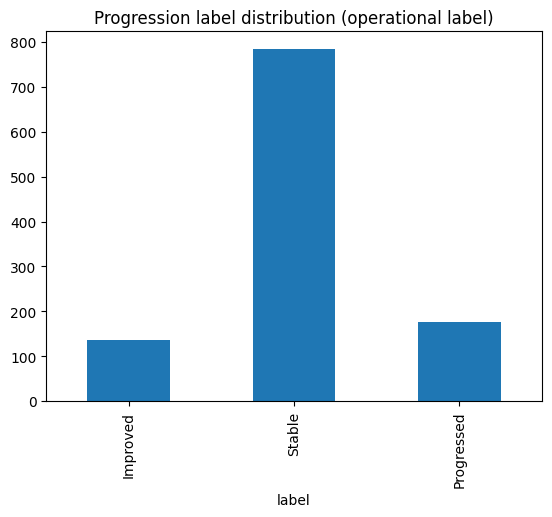

NOTE: labels are operational research labels derived from patient-level grades; they are NOT clinician-confirmed progression labels.


In [ ]:
CLASS_TO_IDX = {"Improved": 0, "Stable": 1, "Progressed": 2}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
CLASS_NAMES = [IDX_TO_CLASS[i] for i in range(len(CLASS_TO_IDX))]
NUM_CLASSES = len(CLASS_NAMES)

GRADE_ORDER = [1, 2, 3, 4, 5]        # ascending severity (dataset card: ETDRS ordinal 1-5). VERIFY against the paper if in doubt.
EXCLUDED_GRADES = [6, 7]             # 6 post-photocoagulation, 7 ungradable (dataset card)

def normalize_grade(v) -> Optional[str]:
    if v is None or pd.isna(v): return None
    s = str(v).strip()
    try:
        f = float(s); return str(int(f)) if f == int(f) else str(f)
    except ValueError: return s
RANK = {normalize_grade(g): i for i, g in enumerate(GRADE_ORDER)}
EXCL = {normalize_grade(g) for g in EXCLUDED_GRADES}

def grade_status(raw):
    n = normalize_grade(raw)
    if n is None: return n, "missing"
    if n in EXCL: return n, "excluded_special_code"
    if n in RANK: return n, "valid"
    return n, "unrecognised_value"

def make_label(bl_rank: int, fu_rank: int, direction: int = +1) -> str:
    d = (fu_rank - bl_rank) * direction
    return "Progressed" if d > 0 else ("Improved" if d < 0 else "Stable")

aud = []
for r in data_df.itertuples():
    bn, bs = grade_status(r.bl_dr_grade); fn, fs = grade_status(r.fu_dr_grade)
    reason = None if (bs == "valid" and fs == "valid") else f"baseline:{bs}; follow-up:{fs}"
    aud.append(dict(pair_id=r.pair_id, pid=r.pid, bl_raw=r.bl_dr_grade, fu_raw=r.fu_dr_grade, bl_norm=bn, fu_norm=fn,
                    bl_status=bs, fu_status=fs, included=reason is None, exclusion_reason=reason,
                    bl_rank=RANK.get(bn) if bs == "valid" else None, fu_rank=RANK.get(fn) if fs == "valid" else None))
audit = pd.DataFrame(aud)
inc = audit[audit.included].copy()
audit["label"] = None
audit.loc[audit.included, "label"] = [make_label(b, f) for b, f in zip(inc.bl_rank, inc.fu_rank)]
audit["label_idx"] = audit["label"].map(CLASS_TO_IDX)
audit.to_csv(Path(RESULTS_DIR) / "label_construction_audit.csv", index=False)

print("Included pairs:", int(audit.included.sum()), "/", len(audit))
print("Exclusion reasons:"); print(audit.loc[~audit.included, "exclusion_reason"].value_counts().to_string())
asc = np.mean([make_label(b, f, +1) == "Progressed" for b, f in zip(inc.bl_rank, inc.fu_rank)])
desc = np.mean([make_label(b, f, -1) == "Progressed" for b, f in zip(inc.bl_rank, inc.fu_rank)])
print(f"\nProgression rate if higher grade = worse (assumed): {asc:.1%} | if reversed: {desc:.1%} | dataset card: 19.2%")
if abs(asc - 0.192) > abs(desc - 0.192): warnings.warn("Reversed grade direction is closer to the card's 19.2%. Re-check the grade direction before trusting labels!")

LABELED = data_df.merge(audit[["pair_id", "included", "exclusion_reason", "label", "label_idx", "bl_rank", "fu_rank"]], on="pair_id", how="left")
usable_df = LABELED[LABELED.included == True].copy(); usable_df["label_idx"] = usable_df["label_idx"].astype(int)
if usable_df.empty: raise RuntimeError("No labelled pairs - check grade columns/values printed above.")
incons = usable_df.groupby("pid")["label"].nunique(); print("Patients with inconsistent labels across their pairs:", int((incons > 1).sum()))
print("\nFinal class distribution (pairs):"); print(usable_df.label.value_counts().reindex(CLASS_NAMES).fillna(0).astype(int).to_string())
print("Patients:", usable_df.pid.nunique())
usable_df.label.value_counts().reindex(CLASS_NAMES).plot(kind="bar", title="Progression label distribution (operational label)"); plt.show()
print("NOTE: labels are operational research labels derived from patient-level grades; they are NOT clinician-confirmed progression labels.")

## SECTION 5 - Image preprocessing
Deterministic pipeline (identical for training and inference): load RGB ▸ field-of-view (FOV) mask ▸ crop to FOV and pad to square ▸ resize ▸ mild illumination correction ▸ mild CLAHE on the lightness channel only ▸ zero outside the FOV. Intensity *normalisation* (ImageNet mean/std) is applied inside the model Dataset. Everything is configurable via `PreprocConfig`; the config hash is part of the cache folder so different settings never mix. **No random augmentation is applied here** (augmentation lives only in the training Dataset).

In [ ]:
@dataclass
class PreprocConfig:
    img_size: int = 512
    fov_threshold: int = 12          # gray level separating the black border from the retina
    crop_margin_frac: float = 0.02
    illumination: str = "background_divide"   # none | background_divide | graham
    illum_sigma_frac: float = 0.08
    illum_strength: float = 0.7      # 0..1 blend between original and corrected lightness (mild by design)
    clahe: bool = True
    clahe_clip: float = 2.0
    clahe_tile: int = 8
    apply_fov_mask: bool = True
    def hash(self) -> str:
        return hashlib.md5(json.dumps(asdict(self), sort_keys=True).encode()).hexdigest()[:8]

PRE_CFG = PreprocConfig()

def load_rgb(path) -> np.ndarray:
    p = str(path)
    if not os.path.isfile(p): raise FileNotFoundError(p)
    bgr = cv2.imread(p, cv2.IMREAD_COLOR)
    if bgr is None or bgr.ndim != 3 or bgr.shape[2] != 3: raise IOError(f"Unreadable or non-RGB image: {p}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def compute_fov_mask(rgb: np.ndarray, thr: int) -> np.ndarray:
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY); h, w = gray.shape
    s = 512.0 / max(h, w)
    small = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else gray
    m = (cv2.GaussianBlur(small, (5, 5), 0) > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n <= 1: raise ValueError("FOV detection failed: no foreground")
    m = (lab == 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m); cv2.drawContours(filled, cnts, -1, 1, thickness=cv2.FILLED)
    if filled.mean() < 0.05: raise ValueError(f"FOV detection failed: area fraction {filled.mean():.3f}")
    return cv2.resize(filled, (w, h), interpolation=cv2.INTER_NEAREST)

def crop_square(rgb, mask, margin_frac):
    ys, xs = np.where(mask > 0)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    mg = int(margin_frac * max(y1 - y0, x1 - x0))
    y0, x0 = max(0, y0 - mg), max(0, x0 - mg); y1, x1 = min(rgb.shape[0], y1 + mg), min(rgb.shape[1], x1 + mg)
    img, m = rgb[y0:y1, x0:x1], mask[y0:y1, x0:x1]
    h, w = img.shape[:2]; side = max(h, w)
    pt, pl = (side - h) // 2, (side - w) // 2
    img = cv2.copyMakeBorder(img, pt, side - h - pt, pl, side - w - pl, cv2.BORDER_CONSTANT, value=0)
    m = cv2.copyMakeBorder(m, pt, side - h - pt, pl, side - w - pl, cv2.BORDER_CONSTANT, value=0)
    return img, m

def correct_illumination(rgb, mask, cfg: PreprocConfig):
    if cfg.illumination == "none": return rgb
    sigma = max(1.0, cfg.illum_sigma_frac * rgb.shape[0])
    if cfg.illumination == "graham":      # aggressive; offered for experiments only
        return cv2.addWeighted(rgb, 4, cv2.GaussianBlur(rgb, (0, 0), sigma), -4, 128)
    if cfg.illumination != "background_divide": raise ValueError(cfg.illumination)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB); L = lab[..., 0].astype(np.float32); m = mask.astype(np.float32)
    bg = cv2.GaussianBlur(L * m, (0, 0), sigma) / (cv2.GaussianBlur(m, (0, 0), sigma) + 1e-6)   # masked blur: border does not bleed in
    target = float(L[mask > 0].mean())
    Lc = np.clip(L * (target / (bg + 1e-3)), 0, 255)
    lab[..., 0] = np.clip(cfg.illum_strength * Lc + (1 - cfg.illum_strength) * L, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def apply_clahe_L(rgb, cfg):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=cfg.clahe_clip, tileGridSize=(cfg.clahe_tile, cfg.clahe_tile)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def preprocess_rgb(rgb: np.ndarray, cfg: PreprocConfig) -> Tuple[np.ndarray, np.ndarray]:
    """Returns (uint8 RGB img_size x img_size x 3, uint8 FOV mask in {0,1})."""
    mask = compute_fov_mask(rgb, cfg.fov_threshold)
    img, m = crop_square(rgb, mask, cfg.crop_margin_frac)
    img = cv2.resize(img, (cfg.img_size, cfg.img_size), interpolation=cv2.INTER_AREA)
    m = cv2.resize(m, (cfg.img_size, cfg.img_size), interpolation=cv2.INTER_NEAREST)
    img = correct_illumination(img, m, cfg)
    if cfg.clahe: img = apply_clahe_L(img, cfg)
    if cfg.apply_fov_mask: img = img * m[..., None]
    assert img.shape == (cfg.img_size, cfg.img_size, 3) and img.dtype == np.uint8
    return img, m

def preprocess_path(path, cfg): return preprocess_rgb(load_rgb(path), cfg)
def write_png(path, rgb):
    ok = cv2.imwrite(str(path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 1])
    if not ok: raise IOError(f"Failed to write {path}")
def write_mask(path, m):
    if not cv2.imwrite(str(path), (m * 255).astype(np.uint8), [cv2.IMWRITE_PNG_COMPRESSION, 1]): raise IOError(f"Failed to write {path}")
def read_png_rgb(path): return load_rgb(path)
def read_mask(path):
    m = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if m is None: raise IOError(f"Cannot read mask {path}")
    return (m > 127).astype(np.uint8)

PREPROC_DIR = Path(PROCESSED_DIR) / f"preproc_{PRE_CFG.hash()}"
for sub in ["baseline", "followup", "registered"]: (PREPROC_DIR / sub).mkdir(parents=True, exist_ok=True)
save_json(asdict(PRE_CFG), PREPROC_DIR / "preproc_config.json")
print("Preprocessing cache:", PREPROC_DIR)

Preprocessing cache: /content/drive/MyDrive/Retinal_CAD/outputs/processed/preproc_6a14f1d4


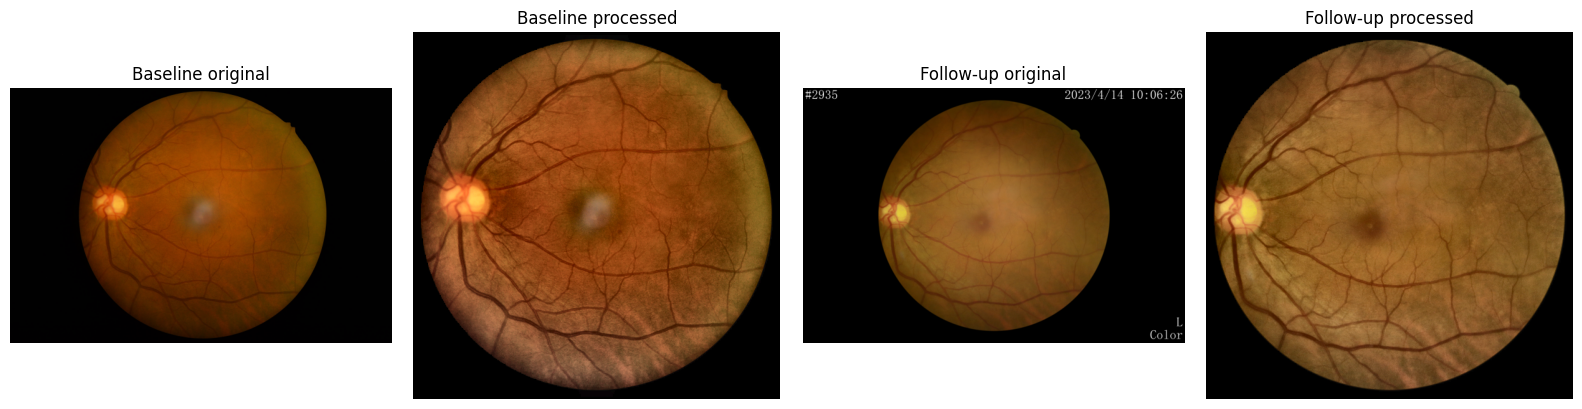

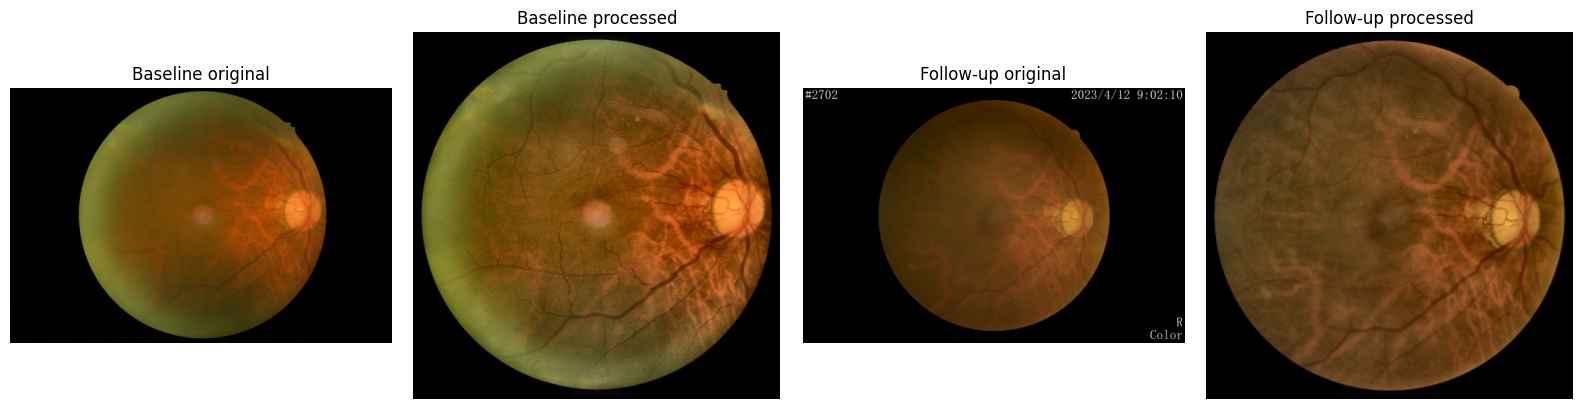

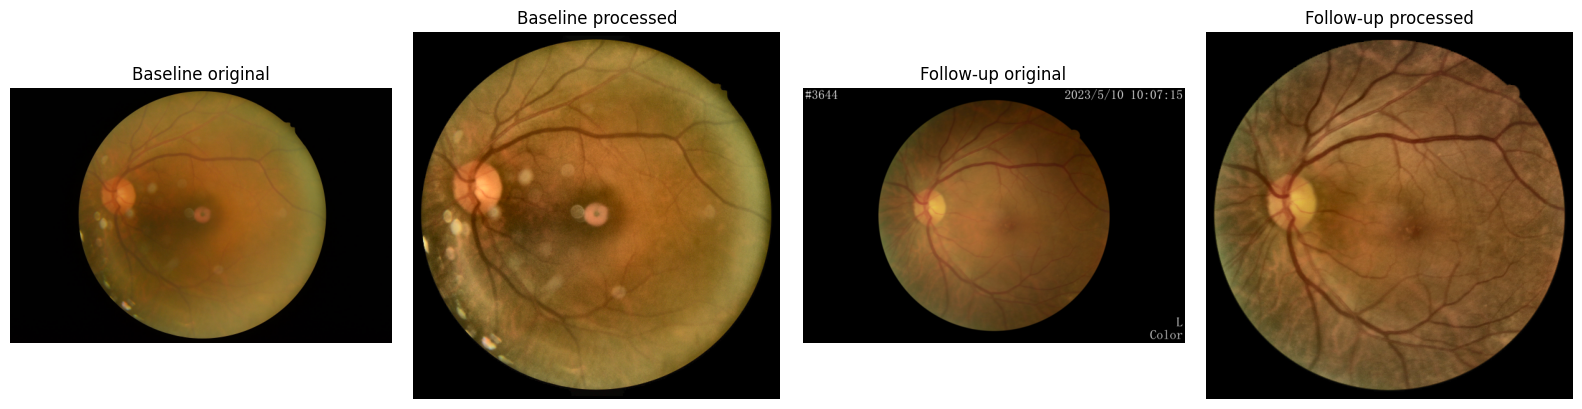

In [ ]:
# Visual comparison: original vs processed on a few random usable pairs
rng = np.random.RandomState(0)
for i in rng.choice(len(usable_df), size=min(3, len(usable_df)), replace=False):
    r = usable_df.iloc[i]
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    try:
        for a, (t, pth) in zip(ax[[0, 2]], [("Baseline original", r.baseline_abs), ("Follow-up original", r.followup_abs)]):
            im = load_rgb(pth); s = 600 / max(im.shape[:2]); a.imshow(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)); a.set_title(t)
        for a, (t, pth) in zip(ax[[1, 3]], [("Baseline processed", r.baseline_abs), ("Follow-up processed", r.followup_abs)]):
            a.imshow(preprocess_path(pth, PRE_CFG)[0]); a.set_title(t)
    except Exception as e:
        print("Preview failed for", r.pair_id, "->", repr(e))
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig(Path(FIGURES_DIR) / f"preproc_compare_{r.pair_id}.png", dpi=100); plt.show()

In [ ]:
# Cache preprocessed images (resume-safe: existing files are reused). Failures are logged, never silently dropped.
def cache_preprocessing(df: pd.DataFrame, cfg: PreprocConfig) -> pd.DataFrame:
    rows = []
    for r in tqdm(df.itertuples(), total=len(df), desc="preprocess"):
        rec = dict(pair_id=r.pair_id, status="ok", reason=None)
        for role, src in (("baseline", r.baseline_abs), ("followup", r.followup_abs)):
            out, mout = PREPROC_DIR / role / f"{r.pair_id}.png", PREPROC_DIR / role / f"{r.pair_id}_mask.png"
            rec[f"{role}_png"], rec[f"{role}_mask_png"] = str(out), str(mout)
            if out.exists() and mout.exists(): continue
            try:
                img, m = preprocess_path(src, cfg); write_png(out, img); write_mask(mout, m)
            except Exception as e:
                rec["status"], rec["reason"] = "failed", f"{role}: {type(e).__name__}: {e}"; break
        rows.append(rec)
    return pd.DataFrame(rows)

preproc_log = cache_preprocessing(usable_df, PRE_CFG)
preproc_log.to_csv(PREPROC_DIR / "preprocessing_log.csv", index=False)
print(preproc_log.status.value_counts().to_string())
failed = preproc_log[preproc_log.status == "failed"]
for r in failed.itertuples(): log_excl(r.pair_id, None, r.reason, "preprocess")
pd.DataFrame(exclusion_log).to_csv(Path(PROCESSED_DIR) / "exclusion_log.csv", index=False)
usable_df = usable_df.merge(preproc_log[preproc_log.status == "ok"].drop(columns=["status", "reason"]), on="pair_id", how="inner").reset_index(drop=True)
print("Pairs after preprocessing:", len(usable_df))
assert len(usable_df) > 0

preprocess:   0%|          | 0/1097 [00:00<?, ?it/s]

status
ok    1097
Pairs after preprocessing: 1097


## SECTION 6 - Baseline / follow-up registration
Registration only *aligns* the follow-up to the baseline; it does **not** replace the corrected eye pairing from `corrected_manifest.csv` (we never re-pair images). Method: SIFT (ORB fallback) on the CLAHE green channel ▸ ratio test ▸ RANSAC similarity transform (rotation+scale+translation, deliberately not a free homography) ▸ optional ECC refinement ▸ quality gate (inliers, sane transform, masked NCC must not get worse). Failed or non-improving registrations keep the un-registered follow-up and are logged with a status; they are never counted as valid registrations. The dataset has no laterality column, so laterality cannot be checked directly; a low NCC/failed status is the safeguard.

In [ ]:
@dataclass
class RegConfig:
    use_sift: bool = True
    max_features: int = 4000
    ratio: float = 0.75
    ransac_thr: float = 4.0
    min_inliers: int = 12
    ecc_refine: bool = True
    ecc_iters: int = 100
    ecc_eps: float = 1e-5
    max_scale_dev: float = 0.25
    max_rot_deg: float = 30.0
    max_shift_frac: float = 0.25
    min_ncc_gain: float = 0.0
    min_ncc_after: float = 0.30     # absolute alignment-quality gate; weak 'improvements' on unrelated images are rejected
REG_CFG = RegConfig()

def _gray_reg(img): return cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(img[..., 1])

def masked_ncc(a, b, m) -> float:
    idx = m > 0
    if int(idx.sum()) < 100: return float("nan")
    x = a[idx].astype(np.float64); y = b[idx].astype(np.float64); x -= x.mean(); y -= y.mean()
    den = np.sqrt((x * x).sum() * (y * y).sum())
    return float((x * y).sum() / den) if den > 0 else float("nan")

def warp_img(img, M, size, interp=cv2.INTER_LINEAR):
    return cv2.warpAffine(img, M, (size[1], size[0]), flags=interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def decompose_affine(M, size):
    A_ = M[:, :2]; scale = float(np.sqrt(abs(np.linalg.det(A_))))
    rot = float(np.degrees(np.arctan2(A_[1, 0], A_[0, 0]))); shift = float(np.hypot(M[0, 2], M[1, 2]) / size)
    return scale, rot, shift

def register_pair(base, fu, mb, mf, cfg: RegConfig) -> dict:
    """Align follow-up to baseline. M maps follow-up -> baseline coordinates (forward). Returns a result dict; never raises on failure."""
    cv2.setRNGSeed(0)
    H, W = base.shape[:2]; res = dict(status="failed", reason=None, method=None, n_matches=0, n_inliers=0, ncc_before=np.nan,
                                      ncc_after=np.nan, scale=np.nan, rot_deg=np.nan, shift_frac=np.nan, M=np.eye(2, 3).tolist(), registered=None, registered_mask=None)
    try:
        gb, gf = _gray_reg(base), _gray_reg(fu); ov0 = (mb & mf).astype(np.uint8)
        res["ncc_before"] = masked_ncc(gb, gf, ov0)
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
        kb, kf = cv2.erode(mb, k), cv2.erode(mf, k)
        use_sift = cfg.use_sift and hasattr(cv2, "SIFT_create")
        det = cv2.SIFT_create(nfeatures=cfg.max_features) if use_sift else cv2.ORB_create(nfeatures=cfg.max_features)
        norm = cv2.NORM_L2 if use_sift else cv2.NORM_HAMMING
        kpb, deb = det.detectAndCompute(gb, kb); kpf, def_ = det.detectAndCompute(gf, kf)
        M = None
        if deb is not None and def_ is not None and len(kpb) >= 8 and len(kpf) >= 8:
            knn = cv2.BFMatcher(norm).knnMatch(def_, deb, k=2)
            good = [p[0] for p in knn if len(p) == 2 and p[0].distance < cfg.ratio * p[1].distance]
            res["n_matches"] = len(good)
            if len(good) >= 4:
                src = np.float32([kpf[m.queryIdx].pt for m in good]); dst = np.float32([kpb[m.trainIdx].pt for m in good])
                M_, inl = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=cfg.ransac_thr, maxIters=5000, confidence=0.99)
                if M_ is not None and inl is not None:
                    res["n_inliers"] = int(inl.sum()); M = M_; res["method"] = "sift" if use_sift else "orb"
        feature_ok = M is not None and res["n_inliers"] >= cfg.min_inliers
        if not feature_ok:
            if not cfg.ecc_refine: res["reason"] = f"too few inliers ({res['n_inliers']})"; return res
            M, res["method"] = np.eye(2, 3), "ecc_only"          # features failed: try intensity-based alignment from identity
        def score(Mx):
            fw, mw = warp_img(gf, Mx, (H, W)), warp_img(mf, Mx, (H, W), cv2.INTER_NEAREST)
            return masked_ncc(gb, fw, (mb & mw).astype(np.uint8))
        ncc_feat = score(M)
        if cfg.ecc_refine:
            try:
                crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, cfg.ecc_iters, cfg.ecc_eps)
                W0 = cv2.invertAffineTransform(M.astype(np.float32)).astype(np.float32)   # ECC uses the inverse-map convention
                _, Wn = cv2.findTransformECC(gb.astype(np.float32) / 255, gf.astype(np.float32) / 255, W0, cv2.MOTION_AFFINE, crit, kb, 5)
                M_ecc = cv2.invertAffineTransform(Wn)
                if (np.isnan(ncc_feat) or score(M_ecc) > ncc_feat):
                    M = M_ecc; res["method"] = (res["method"] or "") + "+ecc"
            except cv2.error as e:
                res["reason"] = f"ecc did not converge ({str(e)[:60]})"
        res["scale"], res["rot_deg"], res["shift_frac"] = decompose_affine(M, H)
        res["M"] = np.asarray(M, dtype=float).tolist(); res["ncc_after"] = score(M)
        sane = abs(res["scale"] - 1) <= cfg.max_scale_dev and abs(res["rot_deg"]) <= cfg.max_rot_deg and res["shift_frac"] <= cfg.max_shift_frac
        if not sane: res["status"], res["reason"] = "failed", "implausible transform"; return res
        if np.isnan(res["ncc_after"]) or res["ncc_after"] < cfg.min_ncc_after:
            res["status"], res["reason"] = "failed", f"alignment quality too low (NCC {res['ncc_after']:.2f} < {cfg.min_ncc_after})"; return res
        if np.isnan(res["ncc_before"]) or res["ncc_after"] < res["ncc_before"] + cfg.min_ncc_gain:
            res["status"], res["reason"] = "identity_kept_no_improvement", "registration did not improve masked NCC"; return res
        res["status"], res["reason"] = "registered", res["reason"]
        res["registered"] = warp_img(fu, M, (H, W)); res["registered_mask"] = warp_img(mf, M, (H, W), cv2.INTER_NEAREST) & mb
        return res
    except Exception as e:                                   # logged, not silent: reason is stored in the registration log
        res["status"], res["reason"] = "failed", f"{type(e).__name__}: {e}"; return res
print("register_pair defined | SIFT available:", hasattr(cv2, "SIFT_create"))

register_pair defined | SIFT available: True


In [ ]:
# Run registration for all pairs (resume-safe) and log every outcome
REG_LOG_PATH = PREPROC_DIR / "registration_log.csv"; REG_MATS_PATH = PREPROC_DIR / "registration_matrices.json"
reg_rows = pd.read_csv(REG_LOG_PATH).to_dict("records") if REG_LOG_PATH.exists() else []
mats = json.load(open(REG_MATS_PATH)) if REG_MATS_PATH.exists() else {}
done = {r["pair_id"] for r in reg_rows}
for r in tqdm(usable_df.itertuples(), total=len(usable_df), desc="registration"):
    if r.pair_id in done: continue
    b, f = read_png_rgb(r.baseline_png), read_png_rgb(r.followup_png); mb, mf = read_mask(r.baseline_mask_png), read_mask(r.followup_mask_png)
    res = register_pair(b, f, mb, mf, REG_CFG)
    reg_path = PREPROC_DIR / "registered" / f"{r.pair_id}.png"
    if res["status"] == "registered":
        write_png(reg_path, res["registered"]); write_mask(PREPROC_DIR / "registered" / f"{r.pair_id}_mask.png", res["registered_mask"])
    mats[r.pair_id] = res["M"]
    reg_rows.append({k: v for k, v in res.items() if k not in ("registered", "registered_mask", "M")} | dict(pair_id=r.pair_id))
    if len(reg_rows) % 100 == 0: pd.DataFrame(reg_rows).to_csv(REG_LOG_PATH, index=False); save_json(mats, REG_MATS_PATH)
reg_log = pd.DataFrame(reg_rows); reg_log.to_csv(REG_LOG_PATH, index=False); save_json(mats, REG_MATS_PATH)
print(reg_log.status.value_counts().to_string()); print(reg_log.groupby("status")[["n_inliers", "ncc_before", "ncc_after"]].median())
print("Failure reasons:"); print(reg_log.loc[reg_log.status != "registered", "reason"].value_counts().head(10).to_string())

usable_df = usable_df.drop(columns=[c for c in usable_df.columns if c.startswith("reg_")], errors="ignore").merge(
    reg_log[["pair_id", "status", "ncc_before", "ncc_after", "n_inliers"]].rename(columns=lambda c: c if c == "pair_id" else "reg_" + c), on="pair_id", how="left")
usable_df["followup_reg_png"] = [str(PREPROC_DIR / "registered" / f"{p}.png") if s == "registered" else None for p, s in zip(usable_df.pair_id, usable_df.reg_status)]
usable_df["followup_reg_mask_png"] = [str(PREPROC_DIR / "registered" / f"{p}_mask.png") if s == "registered" else None for p, s in zip(usable_df.pair_id, usable_df.reg_status)]
use_reg = CFG["use_registered_followup"]
usable_df["fu_model_png"] = [r if (use_reg and r) else f for r, f in zip(usable_df.followup_reg_png, usable_df.followup_png)]
usable_df["fu_model_mask_png"] = [r if (use_reg and r) else f for r, f in zip(usable_df.followup_reg_mask_png, usable_df.followup_mask_png)]
usable_df.to_csv(Path(PROCESSED_DIR) / "usable_pairs.csv", index=False)

registration:   0%|          | 0/1097 [00:00<?, ?it/s]

status
registered    843
failed        254
            n_inliers  ncc_before  ncc_after
status                                      
failed            5.0    0.033045   0.170029
registered       86.0    0.087962   0.488268
Failure reasons:
reason
implausible transform                         19
alignment quality too low (NCC 0.20 < 0.3)    12
alignment quality too low (NCC 0.21 < 0.3)    12
alignment quality too low (NCC 0.25 < 0.3)    11
alignment quality too low (NCC 0.24 < 0.3)    11
alignment quality too low (NCC 0.22 < 0.3)    10
alignment quality too low (NCC 0.11 < 0.3)    10
alignment quality too low (NCC 0.29 < 0.3)    10
alignment quality too low (NCC 0.18 < 0.3)     9
alignment quality too low (NCC 0.27 < 0.3)     8


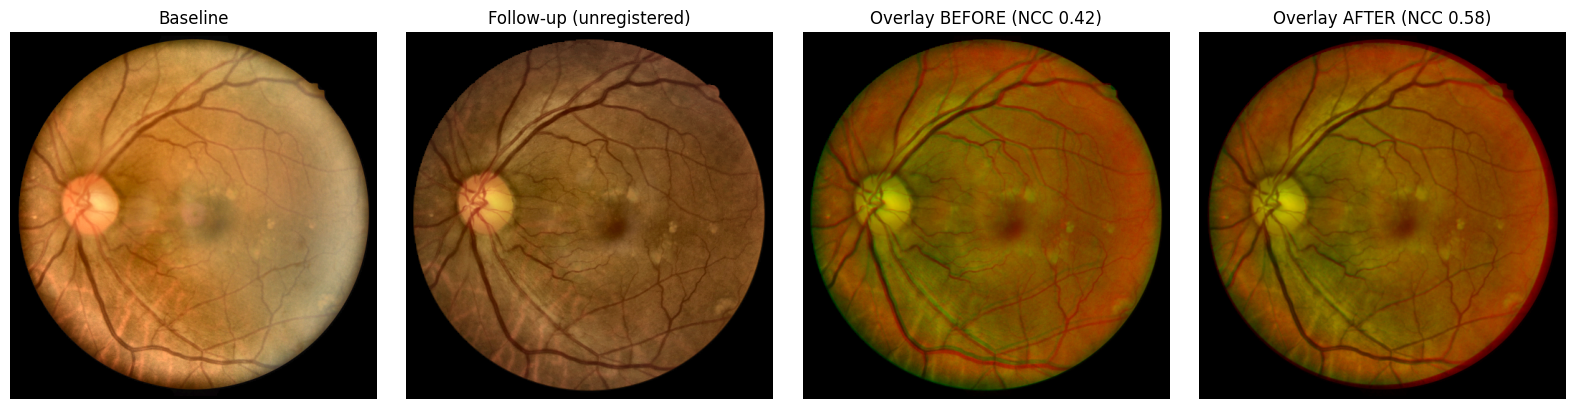

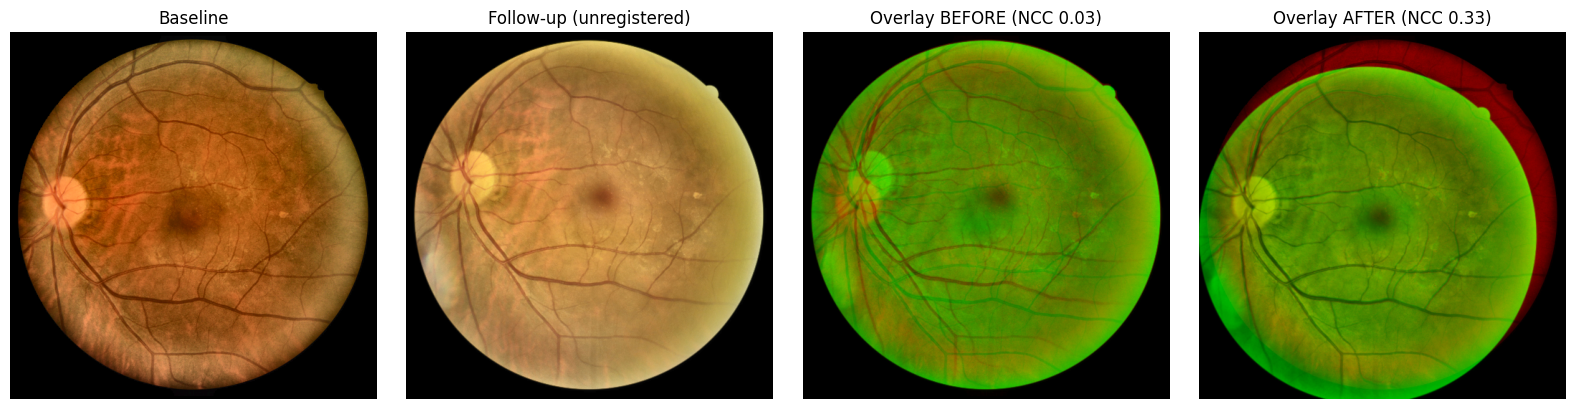

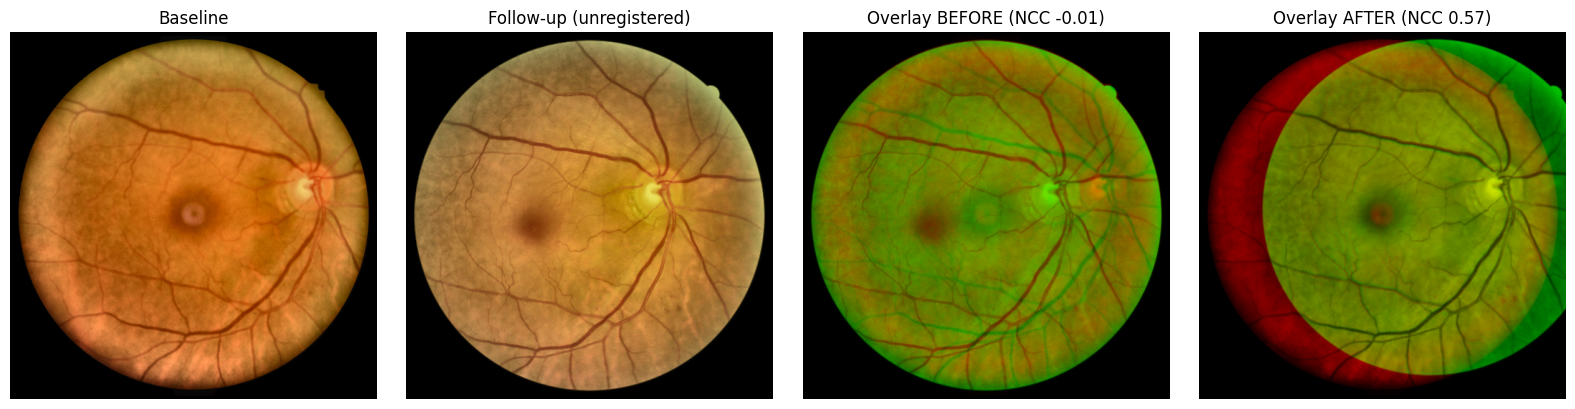

In [ ]:
# Before/after registration: red = baseline, green = follow-up (yellow = aligned structures)
def red_green(a, b):
    ga, gb = a[..., 1], b[..., 1]; return np.stack([ga, gb, np.zeros_like(ga)], -1)
ok = usable_df[usable_df.reg_status == "registered"]
for r in ok.sample(min(3, len(ok)), random_state=1).itertuples():
    b, f, fr = read_png_rgb(r.baseline_png), read_png_rgb(r.followup_png), read_png_rgb(r.followup_reg_png)
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    for a, im, t in zip(ax, [b, f, red_green(b, f), red_green(b, fr)], ["Baseline", "Follow-up (unregistered)", f"Overlay BEFORE (NCC {r.reg_ncc_before:.2f})", f"Overlay AFTER (NCC {r.reg_ncc_after:.2f})"]):
        a.imshow(im); a.set_title(t); a.axis("off")
    plt.tight_layout(); plt.savefig(Path(FIGURES_DIR) / f"registration_{r.pair_id}.png", dpi=100); plt.show()
if len(ok) == 0: print("No successfully registered pair to display - inspect registration_log.csv")

## SECTION 7 - Change detection and visualisation
Three levels: (A) classical image difference (absolute difference, heatmap, overlay, SSIM) restricted to the FOV overlap; (B) FOV-aware metrics; (C) deep feature difference + Grad-CAM (defined after the model, in Section 9b).

**Interpretation warning:** these maps show *intensity/structure differences between visits* inside the retina. They can come from illumination, focus, residual mis-registration or real retinal change. They are **not** validated lesion segmentations; no pixel-level annotation exists, so no change-detection accuracy is claimed.

03245_0 registration: failed | metrics: {'available': True, 'fov_overlap_fraction': 0.699, 'mean_abs_diff': 53.006, 'p95_abs_diff': 89.738, 'fraction_pixels_above_threshold': 0.88, 'threshold_gray_levels': 25.0, 'ssim_masked': 0.5}


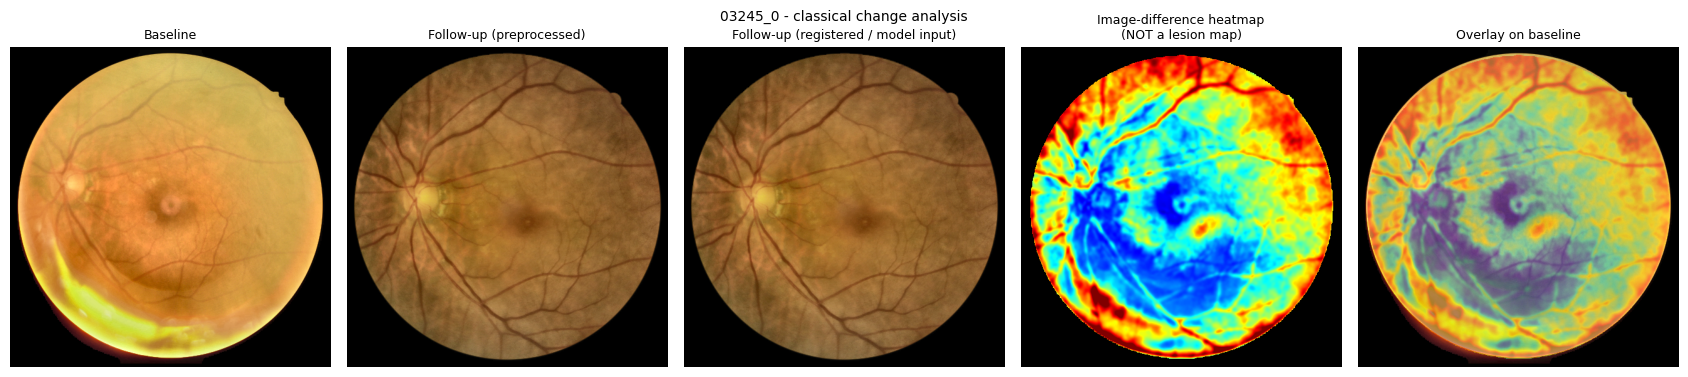

03009_0 registration: registered | metrics: {'available': True, 'fov_overlap_fraction': 0.608, 'mean_abs_diff': 20.772, 'p95_abs_diff': 34.284, 'fraction_pixels_above_threshold': 0.131, 'threshold_gray_levels': 25.0, 'ssim_masked': 0.751}


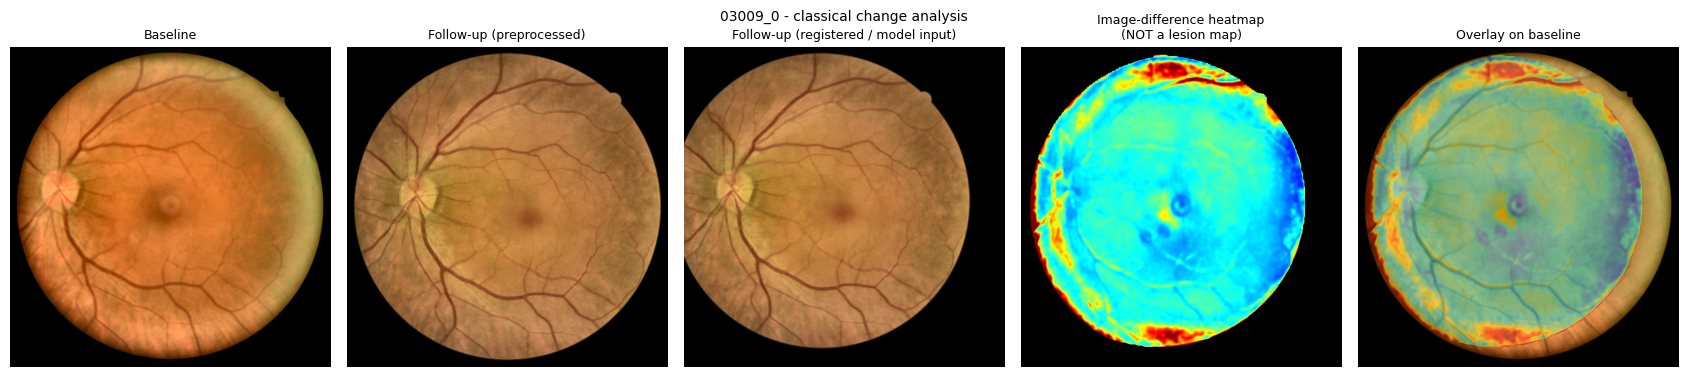

01073_0 registration: registered | metrics: {'available': True, 'fov_overlap_fraction': 0.619, 'mean_abs_diff': 24.041, 'p95_abs_diff': 40.475, 'fraction_pixels_above_threshold': 0.425, 'threshold_gray_levels': 25.0, 'ssim_masked': 0.648}


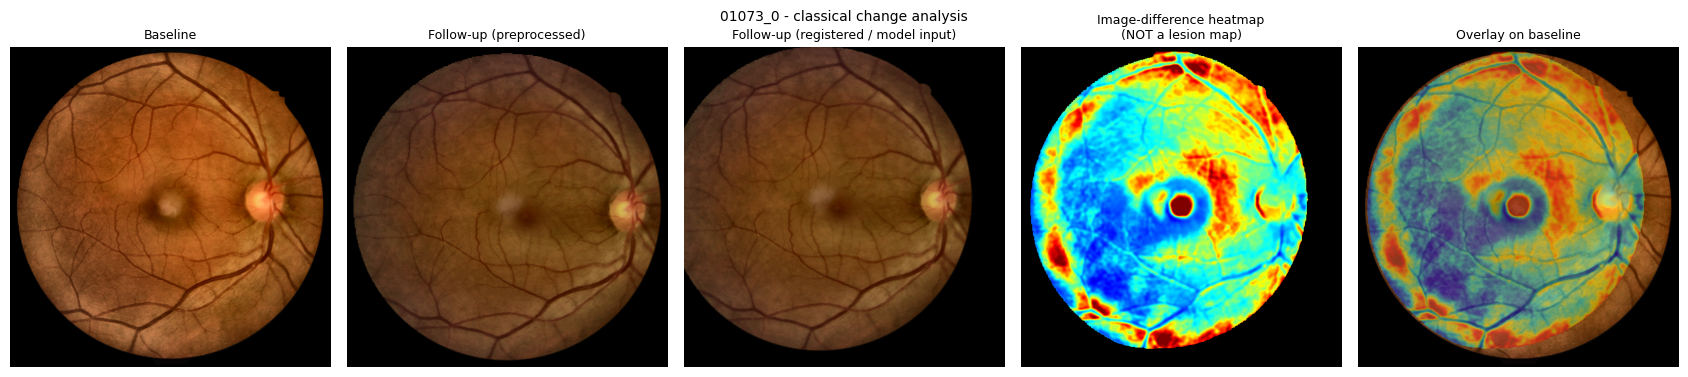

In [ ]:
from skimage.metrics import structural_similarity as sk_ssim

def overlap_mask(mb, mf_reg, erode_px=9):
    m = (mb & mf_reg).astype(np.uint8)
    return cv2.erode(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (erode_px, erode_px))) if erode_px > 1 else m

def abs_diff_map(base, fu_reg, mask, sigma=2.0):
    d = np.abs(base.astype(np.float32) - fu_reg.astype(np.float32)).mean(axis=2)
    d = cv2.GaussianBlur(d, (0, 0), sigma); d[mask == 0] = 0
    return d

def to_heat(vals, mask, vmax=None):
    """vals float map -> RGB heatmap, normalised by the 99th percentile inside the mask."""
    v = vals.astype(np.float32).copy(); inside = v[mask > 0]
    vmax = vmax or (float(np.percentile(inside, 99)) if inside.size else 1.0); vmax = max(vmax, 1e-6)
    heat = cv2.applyColorMap(np.clip(v / vmax * 255, 0, 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB); heat[mask == 0] = 0; return heat

def blend(base, heat, mask, alpha=0.45):
    out = base.copy().astype(np.float32); sel = mask > 0
    out[sel] = (1 - alpha) * out[sel] + alpha * heat[sel]; return out.astype(np.uint8)

def change_metrics(base, fu_reg, mask, thr=25.0) -> dict:
    gb, gf = cv2.cvtColor(base, cv2.COLOR_RGB2GRAY), cv2.cvtColor(fu_reg, cv2.COLOR_RGB2GRAY)
    d = abs_diff_map(base, fu_reg, mask); inside = d[mask > 0]
    if inside.size < 100: return dict(available=False)
    score, smap = sk_ssim(gb, gf, data_range=255, full=True, win_size=7)
    return dict(available=True, fov_overlap_fraction=float((mask > 0).mean()), mean_abs_diff=float(inside.mean()), p95_abs_diff=float(np.percentile(inside, 95)),
                fraction_pixels_above_threshold=float((inside > thr).mean()), threshold_gray_levels=thr, ssim_masked=float(smap[mask > 0].mean()))

def show_change_panel(base, fu_orig, fu_reg, mask, deep=None, title="", save_path=None):
    d = abs_diff_map(base, fu_reg, mask); heat = to_heat(d, mask)
    panels = [(base, "Baseline"), (fu_orig, "Follow-up (preprocessed)"), (fu_reg, "Follow-up (registered / model input)"),
              (heat, "Image-difference heatmap\n(NOT a lesion map)"), (blend(base, heat, mask), "Overlay on baseline")]
    if deep is not None:
        panels.append((blend(fu_reg, to_heat(deep["feature_diff"], mask), mask), "Model feature-difference\n(attention, not lesions)"))
        panels.append((blend(fu_reg, to_heat(deep["gradcam_followup"], mask), mask), "Grad-CAM (predicted class)\n(attention, not lesions)"))
    fig, ax = plt.subplots(1, len(panels), figsize=(3.4 * len(panels), 3.8))
    for a, (im, t) in zip(np.atleast_1d(ax), panels): a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
    fig.suptitle(title, fontsize=10); plt.tight_layout()
    if save_path: Path(save_path).parent.mkdir(parents=True, exist_ok=True); plt.savefig(save_path, dpi=110)
    plt.show(); return d

def load_pair_arrays(row):
    b, fo, fm = read_png_rgb(row.baseline_png), read_png_rgb(row.followup_png), read_png_rgb(row.fu_model_png)
    mb, mfm = read_mask(row.baseline_mask_png), read_mask(row.fu_model_mask_png); return b, fo, fm, overlap_mask(mb, mfm)

for r in usable_df.sample(min(3, len(usable_df)), random_state=3).itertuples():
    b, fo, fm, om = load_pair_arrays(r)
    print(r.pair_id, "registration:", r.reg_status, "| metrics:", {k: round(v, 3) if isinstance(v, float) else v for k, v in change_metrics(b, fm, om).items()})
    show_change_panel(b, fo, fm, om, title=f"{r.pair_id} - classical change analysis", save_path=Path(FIGURES_DIR) / f"change_{r.pair_id}.png")

## SECTION 8 - Patient-level train / validation / test split
Stratified **group** split (groups = patient id) so no patient (and no pair) crosses splits; 80/10/10 as recommended on the dataset card. Split manifests are saved.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit

def patient_level_split(df, label_col="label_idx", group_col="pid", val_frac=0.1, test_frac=0.1, seed=42):
    y, g = df[label_col].values, df[group_col].values
    def first_fold(idx, frac, sd):
        n = max(2, int(round(1 / frac)))
        try:
            sgkf = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=sd)
            return next(iter(sgkf.split(idx, y[idx], g[idx])))
        except ValueError as e:
            print("StratifiedGroupKFold failed (", e, ") -> falling back to GroupShuffleSplit (not stratified)")
            return next(iter(GroupShuffleSplit(n_splits=1, test_size=frac, random_state=sd).split(idx, y[idx], g[idx])))
    all_idx = np.arange(len(df))
    tv, te = first_fold(all_idx, test_frac, seed)
    tv_idx, te_idx = all_idx[tv], all_idx[te]
    tr, va = first_fold(tv_idx, val_frac / (1 - test_frac), seed + 1)
    out = df.copy(); out["split"] = ""
    out.iloc[tv_idx[tr], out.columns.get_loc("split")] = "train"; out.iloc[tv_idx[va], out.columns.get_loc("split")] = "val"; out.iloc[te_idx, out.columns.get_loc("split")] = "test"
    return out

split_df = patient_level_split(usable_df, val_frac=CFG["val_frac"], test_frac=CFG["test_frac"], seed=CFG["seed"])
P = {s: set(split_df.loc[split_df.split == s, "pid"]) for s in ["train", "val", "test"]}
assert not (P["train"] & P["val"] or P["train"] & P["test"] or P["val"] & P["test"]), "PATIENT LEAKAGE between splits!"
assert (split_df.split != "").all()
summ = split_df.groupby("split").agg(patients=("pid", "nunique"), pairs=("pair_id", "count"))
summ = summ.join(pd.crosstab(split_df.split, split_df.label).reindex(columns=CLASS_NAMES, fill_value=0)); display(summ)
for s in ["val", "test"]:
    miss = [c for c in CLASS_NAMES if summ.loc[s, c] == 0]
    if miss: warnings.warn(f"Split '{s}' has no samples for {miss}: metrics for those classes are undefined.")
for s in ["train", "val", "test"]: split_df[split_df.split == s].to_csv(Path(SPLITS_DIR) / f"{s}.csv", index=False)
split_df.to_csv(Path(SPLITS_DIR) / "all_splits.csv", index=False); summ.to_csv(Path(SPLITS_DIR) / "split_summary.csv")
train_df, val_df, test_df = [split_df[split_df.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]

,patients,pairs,Improved,Stable,Progressed
split,,,,,
test,56,108,13,82,13
train,450,879,100,632,147
val,56,110,24,70,16


In [ ]:

train_ids = set(train_df["pid"])
val_ids = set(val_df["pid"])
test_ids = set(test_df["pid"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Patient Leakage Check: PASSED")

for split_name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{split_name} DISTRIBUTION")

    counts = (
        df["label"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )

    print(counts.to_string())

    print(
        "\nPercentages:\n",
        (counts / len(df) * 100).round(2).to_string()
    )


Patient Leakage Check: PASSED

TRAIN DISTRIBUTION
label
Improved      100
Stable        632
Progressed    147

Percentages:
 label
Improved      11.38
Stable        71.90
Progressed    16.72

VALIDATION DISTRIBUTION
label
Improved      24
Stable        70
Progressed    16

Percentages:
 label
Improved      21.82
Stable        63.64
Progressed    14.55

TEST DISTRIBUTION
label
Improved      13
Stable        82
Progressed    13

Percentages:
 label
Improved      12.04
Stable        75.93
Progressed    12.04


In [ ]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32); IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class SiameseCAD(nn.Module):
    def __init__(self, mode="siamese", meta_dim=0, num_classes=NUM_CLASSES, embed_dim=256, dropout=0.3,
                 use_signed_diff=True, pretrained=True, meta_hidden=64):
        super().__init__()
        if mode not in ("baseline_only", "siamese", "siamese_meta"): raise ValueError(mode)
        if mode == "siamese_meta" and meta_dim <= 0: raise ValueError("siamese_meta needs meta_dim > 0")
        self.mode, self.meta_dim, self.num_classes, self.embed_dim = mode, meta_dim, num_classes, embed_dim
        self.dropout, self.use_signed_diff, self.meta_hidden = dropout, use_signed_diff, meta_hidden
        bb = None
        if pretrained:
            try: bb = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
            except Exception as e: print("WARNING: could not load ImageNet weights ->", repr(e), "\n         Training from RANDOM initialisation.")
        if bb is None: bb = torchvision.models.resnet50(weights=None)
        feat_dim = bb.fc.in_features                      # 2048 for ResNet50 (read, not hard-coded)
        self.features = nn.Sequential(bb.conv1, bb.bn1, bb.relu, bb.maxpool, bb.layer1, bb.layer2, bb.layer3, bb.layer4)  # children 0..7
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Sequential(nn.Linear(feat_dim, embed_dim), nn.ReLU(inplace=True), nn.Dropout(dropout))
        n_img = 1 if mode == "baseline_only" else (3 + int(use_signed_diff))
        fusion_dim = n_img * embed_dim
        if mode == "siamese_meta":
            self.meta_mlp = nn.Sequential(nn.Linear(meta_dim, meta_hidden), nn.ReLU(inplace=True), nn.Dropout(dropout),
                                          nn.Linear(meta_hidden, meta_hidden), nn.ReLU(inplace=True))
            fusion_dim += meta_hidden
        self.classifier = nn.Sequential(nn.Linear(fusion_dim, 256), nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(256, num_classes))

    def model_cfg(self) -> dict:
        return dict(mode=self.mode, meta_dim=self.meta_dim, num_classes=self.num_classes, embed_dim=self.embed_dim, dropout=self.dropout,
                    use_signed_diff=self.use_signed_diff, pretrained=False, meta_hidden=self.meta_hidden)

    def train(self, mode: bool = True):
        super().train(mode)
        if mode:   # keep BatchNorm of fully frozen layers in eval mode (stable statistics while the backbone is frozen)
            for m in self.features.modules():
                if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()): m.eval()
        return self

    def forward(self, base, fu=None, meta=None, return_maps=False):
        B = base.shape[0]
        if self.mode == "baseline_only":
            fb = self.features(base); eb = self.proj(self.pool(fb).flatten(1)); fused = eb; ff = None
        else:
            if fu is None: raise ValueError("follow-up image required for siamese modes")
            fm = self.features(torch.cat([base, fu], 0))      # same weights process both visits
            fb, ff = fm[:B], fm[B:]
            if return_maps and torch.is_grad_enabled(): fb.retain_grad(); ff.retain_grad()
            eb, ef = self.proj(self.pool(fb).flatten(1)), self.proj(self.pool(ff).flatten(1))
            parts = [eb, ef, torch.abs(ef - eb)] + ([ef - eb] if self.use_signed_diff else [])
            fused = torch.cat(parts, 1)
        if self.mode == "siamese_meta":
            if meta is None or meta.shape[-1] != self.meta_dim: raise ValueError(f"meta must have shape [B,{self.meta_dim}]")
            fused = torch.cat([fused, self.meta_mlp(meta)], 1)
        logits = self.classifier(fused)
        assert logits.shape == (B, self.num_classes), logits.shape
        out = dict(logits=logits)
        if return_maps: out.update(fmap_b=fb, fmap_f=ff)
        return out

def set_backbone_trainable(model: SiameseCAD, strategy: str):
    layers = list(model.features.children()); idx = {"frozen": [], "layer4": [7], "layer3_4": [6, 7], "full": list(range(8))}
    if strategy not in idx: raise ValueError(strategy)
    for p in model.features.parameters(): p.requires_grad = False
    for i in idx[strategy]:
        for p in layers[i].parameters(): p.requires_grad = True

def img_to_tensor(img: np.ndarray) -> torch.Tensor:
    """uint8 HxWx3 -> normalised float CxHxW. Used by BOTH training Dataset and inference (single code path)."""
    x = (img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

# shape sanity check on CPU with a tiny input (no pretrained download)
_t = SiameseCAD("siamese", pretrained=False); _o = _t(torch.zeros(2, 3, 64, 64), torch.zeros(2, 3, 64, 64))
print("logits:", tuple(_o["logits"].shape), "| params (M):", round(sum(p.numel() for p in _t.parameters()) / 1e6, 1)); del _t, _o

logits: (2, 3) | params (M): 24.3


In [ ]:
def augment_pair(base, fu, cfg=CFG):

    h, w = base.shape[:2]

    # Same geometric transformation for both visits
    angle = random.uniform(
        -cfg["aug_rot_deg"],
        cfg["aug_rot_deg"]
    )

    scale = random.uniform(
        1 - cfg["aug_scale"],
        1 + cfg["aug_scale"]
    )

    M = cv2.getRotationMatrix2D(
        (w / 2, h / 2),
        angle,
        scale
    )

    M[:, 2] += (
        random.uniform(-1, 1) * cfg["aug_shift_frac"] * w,
        random.uniform(-1, 1) * cfg["aug_shift_frac"] * h
    )

    images = []

    for img in (base, fu):

        transformed = cv2.warpAffine(
            img,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        images.append(transformed)

    # No horizontal flipping:
    # Preserve retinal laterality

    # Mild photometric augmentation
    result = []

    for img in images:

        contrast = random.uniform(0.95, 1.05)
        brightness = random.uniform(-5, 5)

        img = img.astype(np.float32)

        img = img * contrast + brightness

        img = np.clip(img, 0, 255).astype(np.uint8)

        result.append(np.ascontiguousarray(img))

    return result[0], result[1]

class LongitudinalDataset(Dataset):
    def __init__(self, df: pd.DataFrame, meta: Optional[np.ndarray], train: bool, base_col="baseline_png", fu_col="fu_model_png"):
        self.df = df.reset_index(drop=True); self.train = train; self.base_col, self.fu_col = base_col, fu_col
        self.meta = meta if meta is not None else np.zeros((len(self.df), 0), np.float32)
        assert len(self.meta) == len(self.df), "meta/dataframe length mismatch"
        self.y = self.df["label_idx"].astype(int).values
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        b, f = read_png_rgb(self.df.at[i, self.base_col]), read_png_rgb(self.df.at[i, self.fu_col])
        if self.train: b, f = augment_pair(b, f)
        return img_to_tensor(b), img_to_tensor(f), torch.from_numpy(self.meta[i].astype(np.float32)), int(self.y[i])

def _worker_init(wid): random.seed(CFG["seed"] + wid); np.random.seed(CFG["seed"] + wid)
def make_loader(ds, shuffle):
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, num_workers=CFG["num_workers"], pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=_worker_init, generator=g, persistent_workers=CFG["num_workers"] > 0)

## SECTION 10 - Clinical metadata preprocessing and fusion branch
Numeric: median imputation (+ missing indicator) and standardisation. Categorical: most-frequent imputation and one-hot (unknown categories ignored). **Fitted on the training split only**, then applied to validation/test/inference. The fitted transformer is saved with the checkpoint.

In [ ]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def clean_meta_df(df: pd.DataFrame, num_cols: List[str], cat_cols: List[str]) -> pd.DataFrame:
    """Deterministic cleaning used in training AND inference. Missing columns become NaN (later imputed)."""
    out = pd.DataFrame(index=df.index)
    for c in num_cols: out[c] = pd.to_numeric(df[c], errors="coerce") if c in df.columns else np.nan
    for c in cat_cols:
        s = df[c] if c in df.columns else pd.Series(np.nan, index=df.index)
        out[c] = s.map(lambda v: np.nan if pd.isna(v) else str(v).strip().lower()).astype(object)
    return out

def build_meta_transformer(num_cols, cat_cols) -> ColumnTransformer:
    tf = []
    if num_cols: tf.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), num_cols))
    if cat_cols: tf.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols))
    return ColumnTransformer(tf, remainder="drop", sparse_threshold=0.0)

META_COLS_ALL = META_NUMERIC + META_CATEGORICAL
if META_COLS_ALL:
    assert_no_leakage(META_COLS_ALL)
    meta_tf = build_meta_transformer(META_NUMERIC, META_CATEGORICAL)
    X_tr = meta_tf.fit_transform(clean_meta_df(train_df, META_NUMERIC, META_CATEGORICAL)).astype(np.float32)   # FIT ON TRAIN ONLY
    X_va = meta_tf.transform(clean_meta_df(val_df, META_NUMERIC, META_CATEGORICAL)).astype(np.float32)
    X_te = meta_tf.transform(clean_meta_df(test_df, META_NUMERIC, META_CATEGORICAL)).astype(np.float32)
    META_DIM = X_tr.shape[1]
    assert np.isfinite(X_tr).all() and np.isfinite(X_va).all() and np.isfinite(X_te).all()
    print("Metadata feature dimension after encoding:", META_DIM)
    try: print("Encoded feature names:", list(meta_tf.get_feature_names_out()))
    except Exception as e: print("(feature names unavailable:", e, ")")
    joblib.dump(dict(transformer=meta_tf, num_cols=META_NUMERIC, cat_cols=META_CATEGORICAL), Path(RESULTS_DIR) / "meta_transformer.joblib")
    save_json(dict(numeric=META_NUMERIC, categorical=META_CATEGORICAL, source="Baseline sheet only", baseline_grade_used=USE_BASELINE_GRADE_AS_FEATURE), Path(RESULTS_DIR) / "metadata_features.json")
else:
    meta_tf, X_tr, X_va, X_te, META_DIM = None, None, None, None, 0
    print("No metadata -> E3 disabled.")

Metadata feature dimension after encoding: 4
Encoded feature names: ['num__bl_age', 'num__bl_hba1c', 'cat__bl_sex_1.0', 'cat__bl_sex_2.0']


## SECTION 11 - Training pipeline
AdamW (backbone/head learning rates), cosine schedule, mixed precision, gradient clipping, class-weighted cross-entropy (weights from the **training split only**), warm-up with a frozen backbone then partial/full fine-tuning, early stopping and model selection on **validation macro-F1** (over classes present in validation). `last.pt` is written every epoch so training can **resume** after a Colab disconnect. The test set is never touched here.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve)

def safe_macro_f1(y_true, y_pred) -> float:
    labels = sorted(set(int(v) for v in y_true))      # only classes actually present -> absent classes do not deflate the score
    return float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)) if labels else float("nan")

def compute_metrics(y_true, probs, class_names=CLASS_NAMES) -> dict:
    y_true = np.asarray(y_true).astype(int); probs = np.asarray(probs); y_pred = probs.argmax(1); K = len(class_names); labels = list(range(K))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels); per = {}; aucs = {}
    for k, name in enumerate(class_names):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = cm.sum() - TP - FN - FP
        pos = int((y_true == k).sum())
        auc = float(roc_auc_score((y_true == k).astype(int), probs[:, k])) if 0 < pos < len(y_true) else None   # OvR AUC needs both pos and neg
        aucs[name] = auc
        per[name] = dict(precision=float(p[k]), recall_sensitivity=float(r[k]), f1=float(f[k]), support=int(s[k]),
                         specificity=float(TN / (TN + FP)) if (TN + FP) > 0 else None, roc_auc_ovr=auc)
    valid = [v for v in aucs.values() if v is not None]
    return dict(n=int(len(y_true)), accuracy=float(accuracy_score(y_true, y_pred)), macro_f1_present_classes=safe_macro_f1(y_true, y_pred),
                macro_f1_all_classes=float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
                weighted_f1=float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
                macro_roc_auc_ovr=float(np.mean(valid)) if valid else None, per_class=per, confusion_matrix=cm.tolist(),
                classification_report=classification_report(y_true, y_pred, labels=labels, target_names=class_names, zero_division=0, output_dict=True))

def class_weights_from_train(y_train, K=NUM_CLASSES) -> torch.Tensor:
    cnt = np.bincount(np.asarray(y_train).astype(int), minlength=K).astype(np.float64)
    w = np.where(cnt > 0, cnt.sum() / (K * np.maximum(cnt, 1)), 0.0)
    if (cnt == 0).any(): print("WARNING: classes absent from the training split:", [CLASS_NAMES[i] for i in np.where(cnt == 0)[0]])
    return torch.tensor(w, dtype=torch.float32)

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None; model.train(train); tot, n = 0.0, 0; ys, ps = [], []
    amp = CFG["use_amp"] and DEVICE.type == "cuda"
    for base, fu, meta, y in tqdm(loader, leave=False, desc="train" if train else "eval"):
        base, fu, meta, y = base.to(DEVICE, non_blocking=True), fu.to(DEVICE, non_blocking=True), meta.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                logits = model(base, fu, meta)["logits"]
            loss = criterion(logits.float(), y)
        if not torch.isfinite(loss): raise FloatingPointError("Non-finite loss - lower the learning rate or check the data.")
        if train:
            optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            if CFG["grad_clip"]: scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
            scaler.step(optimizer); scaler.update()
        tot += loss.item() * len(y); n += len(y); ys.append(y.cpu().numpy()); ps.append(logits.detach().float().softmax(1).cpu().numpy())
    y_true, probs = np.concatenate(ys), np.concatenate(ps)
    return tot / max(n, 1), float((probs.argmax(1) == y_true).mean()), y_true, probs

def predict_loader(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for base, fu, meta, y in tqdm(loader, leave=False, desc="predict"):
            lg = model(base.to(DEVICE), fu.to(DEVICE), meta.to(DEVICE))["logits"]
            ys.append(y.numpy()); ps.append(lg.float().softmax(1).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps)

def localize(df, cols):
    """Copy processed images to the fast local disk (Drive reads are slow during training); returns df with updated paths."""
    df = df.copy()
    for c in cols:
        new = []
        for p in df[c]:
            dst = Path(LOCAL_CACHE) / Path(p).relative_to(PROCESSED_DIR)
            if not dst.exists(): dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, dst)
            new.append(str(dst))
        df[c] = new
    return df
LOCALIZE = True
if LOCALIZE:
    NEED = ["baseline_png", "fu_model_png"]
    train_df, val_df, test_df = [localize(d, NEED) for d in (train_df, val_df, test_df)]
    print("Processed images copied to", LOCAL_CACHE)

Processed images copied to /content/local_cache


In [ ]:

def atomic_save(obj, path):
    tmp = str(path) + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


EXPERIMENTS = {
    "E3": {
        "mode": "siamese_meta",
        "use_meta": True
    }
}


def strategy_for_epoch(epoch):
    if epoch < CFG["warmup_epochs"]:
        return "frozen"

    return CFG["unfreeze"]


def load_best(exp_dir, model):

    ck = torch.load(
        exp_dir / "best.pt",
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(ck["model"])

    return ck


def train_experiment(name, spec):

    exp_dir = Path(CHECKPOINT_DIR) / name
    exp_dir.mkdir(parents=True, exist_ok=True)

    use_meta = spec["use_meta"]
    mdim = META_DIM if use_meta else 0

    if use_meta and mdim == 0:
        raise ValueError(
            "E3 requires valid metadata features."
        )

    mtr = X_tr if use_meta else None
    mva = X_va if use_meta else None

    # Balanced training data
    train_dataset = LongitudinalDataset(
        train_df, mtr, True
    )

    train_loader = make_balanced_train_loader(
        train_dataset, train_df
    )

    # Natural validation distribution
    val_loader = make_loader(
        LongitudinalDataset(val_df, mva, False),
        False
    )

    # Model
    model = SiameseCAD(
        mode=spec["mode"],
        meta_dim=mdim,
        embed_dim=CFG["embed_dim"],
        dropout=CFG["dropout"],
        use_signed_diff=CFG["use_signed_diff"]
    ).to(DEVICE)

    print("\n" + "=" * 60)
    print("FINAL TRAINING CONFIGURATION")
    print("=" * 60)
    print("Experiment       :", name)
    print("Architecture     : Siamese ResNet50 + Metadata")
    print("Training samples :", len(train_df))
    print("Validation samples:", len(val_df))
    print("Metadata features:", mdim)
    print("Device           :", DEVICE)
    print("Backbone LR      :", CFG["lr_backbone"])
    print("Head LR          :", CFG["lr_head"])
    print("Batch size       :", CFG["batch_size"])
    print("=" * 60)

    # Loss: balancing is handled by WeightedRandomSampler
    criterion = nn.CrossEntropyLoss(
        label_smoothing=CFG["label_smoothing"]
    )

    # Separate learning rates
    backbone_params = list(model.features.parameters())

    backbone_ids = {
        id(p) for p in backbone_params
    }

    head_params = [
        p for p in model.parameters()
        if id(p) not in backbone_ids
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": backbone_params,
                "lr": CFG["lr_backbone"]
            },
            {
                "params": head_params,
                "lr": CFG["lr_head"]
            }
        ],
        weight_decay=CFG["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=CFG["epochs"]
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=CFG["use_amp"] and DEVICE.type == "cuda"
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_macro_f1": []
    }

    start_epoch = 0
    best_f1 = -1.0
    best_loss = float("inf")
    bad_epochs = 0

    last_path = exp_dir / "last.pt"

    # Resume only when retraining is disabled
    if last_path.exists() and not CFG["retrain"]:

        ck = torch.load(
            last_path,
            map_location=DEVICE,
            weights_only=False
        )

        if ck["model_cfg"] != model.model_cfg():
            raise RuntimeError(
                "Checkpoint architecture mismatch."
            )

        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])

        start_epoch = ck["epoch"] + 1
        best_f1 = ck["best_f1"]
        best_loss = ck["best_loss"]
        bad_epochs = ck["bad"]
        history = ck["history"]

        print("Resuming from epoch:", start_epoch + 1)

    # Training loop
    for epoch in range(start_epoch, CFG["epochs"]):

        current_strategy = strategy_for_epoch(epoch)

        set_backbone_trainable(
            model,
            current_strategy
        )

        start_time = time.time()

        train_loss, train_acc, _, _ = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        val_loss, val_acc, val_y, val_probs = run_epoch(
            model,
            val_loader,
            criterion
        )

        val_predictions = val_probs.argmax(axis=1)

        # Evaluate all three classes
        val_f1 = f1_score(
            val_y,
            val_predictions,
            labels=list(range(NUM_CLASSES)),
            average="macro",
            zero_division=0
        )

        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["train_acc"].append(float(train_acc))
        history["val_acc"].append(float(val_acc))
        history["val_macro_f1"].append(float(val_f1))

        scheduler.step()

        improved = (
            val_f1 > best_f1 + 1e-6
            or (
                abs(val_f1 - best_f1) <= 1e-6
                and val_loss < best_loss
            )
        )

        if improved:

            best_f1 = val_f1
            best_loss = val_loss
            bad_epochs = 0

            atomic_save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "val_macro_f1": val_f1,
                    "val_loss": val_loss,
                    "model_cfg": model.model_cfg()
                },
                exp_dir / "best.pt"
            )

        else:
            bad_epochs += 1

        # Save resume checkpoint
        atomic_save(
            {
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(),
                "epoch": epoch,
                "best_f1": best_f1,
                "best_loss": best_loss,
                "bad": bad_epochs,
                "history": history,
                "model_cfg": model.model_cfg()
            },
            last_path
        )

        save_json(
            history,
            exp_dir / "history.json"
        )

        elapsed = time.time() - start_time

        print("\n" + "-" * 60)
        print(f"EPOCH {epoch + 1:02d}/{CFG['epochs']}")
        print("-" * 60)

        print(
            f"Training Loss       : {train_loss:.4f}"
        )

        print(
            f"Validation Loss     : {val_loss:.4f}"
        )

        print(
            f"Training Accuracy   : {train_acc * 100:.2f}%"
        )

        print(
            f"Validation Accuracy : {val_acc * 100:.2f}%"
        )

        print(
            f"Validation Macro-F1 : {val_f1:.4f}"
        )

        print(
            f"Best Validation F1  : {best_f1:.4f}"
        )

        print(
            f"Backbone Strategy   : {current_strategy}"
        )

        print(
            f"Learning Rate       : "
            f"{optimizer.param_groups[0]['lr']:.7f}"
        )

        print(
            f"Early Stop Counter  : "
            f"{bad_epochs}/{CFG['patience']}"
        )

        print(
            f"Epoch Duration      : {elapsed:.1f} seconds"
        )

        print(
            "Checkpoint Updated  :",
            "YES" if improved else "NO"
        )

        if bad_epochs >= CFG["patience"]:

            print("\nEARLY STOPPING ACTIVATED")
            print("Best validation Macro-F1:", best_f1)

            break

    if not (exp_dir / "best.pt").exists():
        raise RuntimeError("No best checkpoint was generated.")

    # Restore best validation model
    best_checkpoint = load_best(
        exp_dir,
        model
    )

    # Save experiment configuration
    save_json(
        {
            "experiment": name,
            "model_cfg": model.model_cfg(),
            "training_cfg": CFG,
            "preprocessing_cfg": asdict(PRE_CFG),
            "registration_cfg": asdict(REG_CFG),
            "class_to_idx": CLASS_TO_IDX,
            "metadata_numeric": META_NUMERIC,
            "metadata_categorical": META_CATEGORICAL,
            "metadata_dim": mdim,
            "use_registered_followup": CFG[
                "use_registered_followup"
            ],
            "selection_metric": "validation_macro_f1"
        },
        exp_dir / "config.json"
    )

    if use_meta:

        joblib.dump(
            {
                "transformer": meta_tf,
                "num_cols": META_NUMERIC,
                "cat_cols": META_CATEGORICAL
            },
            exp_dir / "meta_transformer.joblib"
        )

    save_json(
        {"finished": True},
        exp_dir / "training_complete.json"
    )

    print("\nTRAINING COMPLETED SUCCESSFULLY")
    print("Best epoch:", best_checkpoint["epoch"] + 1)
    print("Best validation Macro-F1:",
          f"{best_checkpoint['val_macro_f1']:.4f}")

    return model, history


print("Final training pipeline ready.")


Final training pipeline ready.


In [ ]:
def make_balanced_train_loader(dataset, df):
    # Count classes to compute weights for a balanced WeightedRandomSampler
    y_train = df["label_idx"].values
    class_counts = np.bincount(y_train)
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[y_train]

    sampler = torch.utils.data.WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

    g = torch.Generator()
    g.manual_seed(CFG["seed"])

    return DataLoader(
        dataset,
        batch_size=CFG["batch_size"],
        sampler=sampler,
        num_workers=CFG["num_workers"],
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=_worker_init,
        generator=g,
        persistent_workers=CFG["num_workers"] > 0
    )

EXP_MODELS, EXP_HIST, EXP_RESULTS = {}, {}, {}
for name in RUN_EXPERIMENTS:
    spec = EXPERIMENTS[name]
    if spec["use_meta"] and META_DIM == 0: print(f"Skipping {name}: no metadata."); continue
    print(f"\n===== {name}: {spec['mode']} =====")
    EXP_MODELS[name], EXP_HIST[name] = train_experiment(name, spec)
    torch.cuda.empty_cache()


===== E3: siamese_meta =====
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 179MB/s]



FINAL TRAINING CONFIGURATION
Experiment       : E3
Architecture     : Siamese ResNet50 + Metadata
Training samples : 879
Validation samples: 110
Metadata features: 4
Device           : cuda
Backbone LR      : 1e-05
Head LR          : 0.0002
Batch size       : 8


train:   0%|          | 0/110 [00:00<?, ?it/s]

eval:   0%|          | 0/14 [00:00<?, ?it/s]


------------------------------------------------------------
EPOCH 01/30
------------------------------------------------------------
Training Loss       : 1.0894
Validation Loss     : 1.0875
Training Accuracy   : 40.39%
Validation Accuracy : 33.64%
Validation Macro-F1 : 0.3119
Best Validation F1  : 0.3119
Backbone Strategy   : frozen
Learning Rate       : 0.0000100
Early Stop Counter  : 0/6
Epoch Duration      : 41.6 seconds
Checkpoint Updated  : YES


... (20 outputs left out)


------------------------------------------------------------
EPOCH 08/30
------------------------------------------------------------
Training Loss       : 0.5767
Validation Loss     : 1.4787
Training Accuracy   : 78.50%
Validation Accuracy : 38.18%
Validation Macro-F1 : 0.3123
Best Validation F1  : 0.3682
Backbone Strategy   : layer3_4
Learning Rate       : 0.0000083
Early Stop Counter  : 5/6
Epoch Duration      : 47.4 seconds
Checkpoint Updated  : NO


train:   0%|          | 0/110 [00:00<?, ?it/s]

eval:   0%|          | 0/14 [00:00<?, ?it/s]


------------------------------------------------------------
EPOCH 09/30
------------------------------------------------------------
Training Loss       : 0.4865
Validation Loss     : 1.6943
Training Accuracy   : 82.82%
Validation Accuracy : 46.36%
Validation Macro-F1 : 0.3594
Best Validation F1  : 0.3682
Backbone Strategy   : layer3_4
Learning Rate       : 0.0000079
Early Stop Counter  : 6/6
Epoch Duration      : 47.1 seconds
Checkpoint Updated  : NO

EARLY STOPPING ACTIVATED
Best validation Macro-F1: 0.3681645678799379

TRAINING COMPLETED SUCCESSFULLY
Best epoch: 3
Best validation Macro-F1: 0.3682


## SECTION 12 - Evaluation
Validation metrics are used for model selection; the held-out test set is evaluated once per experiment after training. Metrics that are mathematically undefined (e.g. ROC-AUC for a class with no test positives) are reported as `None`, not as zeros. **Progression classification and change visualisation are separate tasks; no change-detection accuracy is claimed** (no pixel/region ground truth).


Evaluating: E3


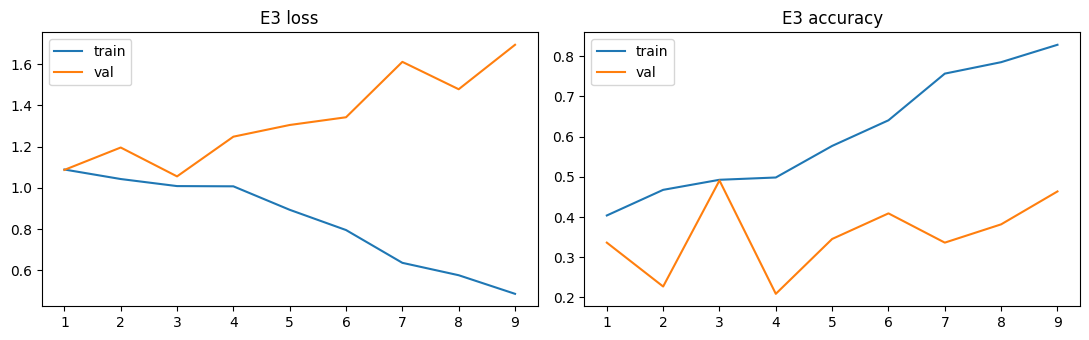

predict:   0%|          | 0/14 [00:00<?, ?it/s]


       E3 | VALIDATION RESULTS
Number of Samples : 110
Accuracy         : 49.09%
Macro F1         : 0.3682
Weighted F1      : 0.4922
Macro ROC-AUC    : 0.5166

PER-CLASS PERFORMANCE
----------------------------------------------------------------------
            Precision  Recall  F1-Score  Specificity  ROC-AUC  Samples
Class                                                                 
Improved       0.2368  0.3750    0.2903       0.6628   0.4787       24
Stable         0.6515  0.6143    0.6324       0.4250   0.5218       70
Progressed     0.3333  0.1250    0.1818       0.9574   0.5492       16

CONFUSION MATRIX
----------------------------------------------------------------------
                   Predicted Improved  Predicted Stable  Predicted Progressed
Actual Improved                     9                14                     1
Actual Stable                      24                43                     3
Actual Progressed                   5                 9             

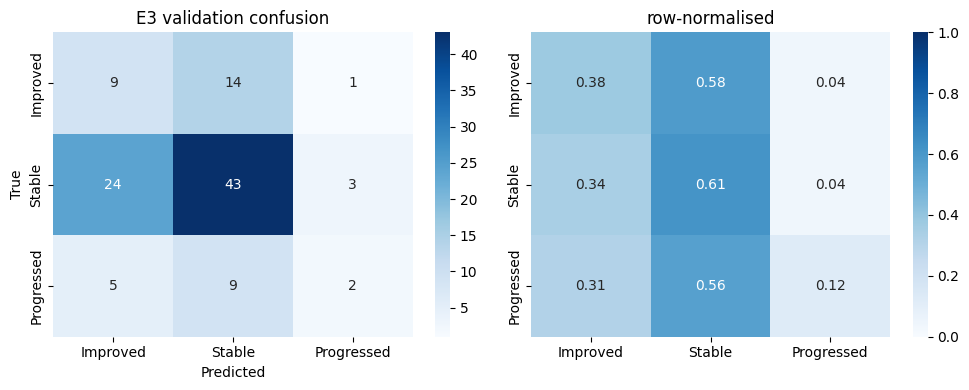

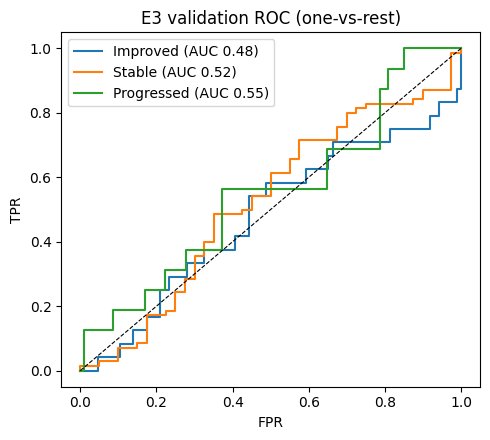

predict:   0%|          | 0/14 [00:00<?, ?it/s]


       E3 | TEST RESULTS
Number of Samples : 108
Accuracy         : 42.59%
Macro F1         : 0.3247
Weighted F1      : 0.4908
Macro ROC-AUC    : 0.5196

PER-CLASS PERFORMANCE
----------------------------------------------------------------------
            Precision  Recall  F1-Score  Specificity  ROC-AUC  Samples
Class                                                                 
Improved       0.1111  0.4615    0.1791       0.4947   0.4615       13
Stable         0.7917  0.4634    0.5846       0.6154   0.5483       82
Progressed     0.3333  0.1538    0.2105       0.9579   0.5490       13

CONFUSION MATRIX
----------------------------------------------------------------------
                   Predicted Improved  Predicted Stable  Predicted Progressed
Actual Improved                     6                 7                     0
Actual Stable                      40                38                     4
Actual Progressed                   8                 3                   

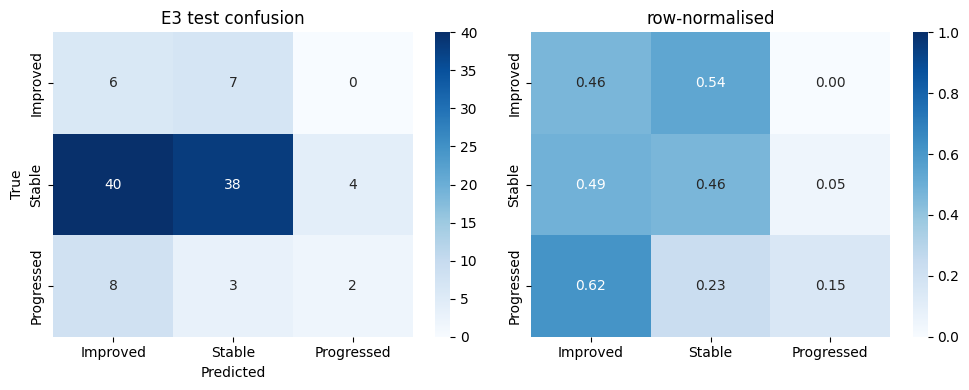

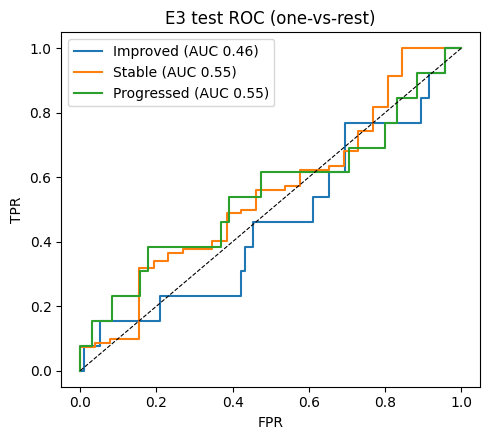


             FINAL MODEL PERFORMANCE SUMMARY
       Validation Accuracy (%)  Validation Macro-F1  Test Accuracy (%)  Test Macro-F1  Test Weighted-F1  Test Macro-AUC
Model                                                                                                                  
E3                     49.0909               0.3682            42.5926         0.3247            0.4908          0.5196

Results saved successfully.


In [ ]:
def plot_history(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); e = range(1, len(h["train_loss"]) + 1)
    ax[0].plot(e, h["train_loss"], label="train"); ax[0].plot(e, h["val_loss"], label="val"); ax[0].set_title(f"{name} loss"); ax[0].legend()
    ax[1].plot(e, h["train_acc"], label="train"); ax[1].plot(e, h["val_acc"], label="val"); ax[1].set_title(f"{name} accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(Path(FIGURES_DIR) / f"{name}_history.png", dpi=110); plt.show()

def plot_confusion(cm, name, split):
    cm = np.array(cm); fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0]); ax[0].set_title(f"{name} {split} confusion"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    sns.heatmap(norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1]); ax[1].set_title("row-normalised")
    plt.tight_layout(); plt.savefig(Path(FIGURES_DIR) / f"{name}_{split}_confusion.png", dpi=110); plt.show()

def plot_roc(y, probs, name, split):
    plt.figure(figsize=(5, 4.5)); n_ok = 0
    for k, c in enumerate(CLASS_NAMES):
        yk = (np.asarray(y) == k).astype(int)
        if 0 < yk.sum() < len(yk):
            fpr, tpr, _ = roc_curve(yk, probs[:, k]); plt.plot(fpr, tpr, label=f"{c} (AUC {roc_auc_score(yk, probs[:, k]):.2f})"); n_ok += 1
        else: print(f"ROC for '{c}' undefined (no positives or no negatives in {split})")
    plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"{name} {split} ROC (one-vs-rest)")
    if n_ok: plt.legend()
    plt.tight_layout(); plt.savefig(Path(FIGURES_DIR) / f"{name}_{split}_roc.png", dpi=110); plt.show()

def print_metrics_report(metrics, split_name, model_name):

    print("\n" + "=" * 70)
    print(f"       {model_name} | {split_name.upper()} RESULTS")
    print("=" * 70)

    print(f"Number of Samples : {metrics['n']}")

    print(
        f"Accuracy         : "
        f"{metrics['accuracy'] * 100:.2f}%"
    )

    print(
        f"Macro F1         : "
        f"{metrics['macro_f1_all_classes']:.4f}"
    )

    print(
        f"Weighted F1      : "
        f"{metrics['weighted_f1']:.4f}"
    )

    auc = metrics["macro_roc_auc_ovr"]

    print(
        f"Macro ROC-AUC    : "
        f"{auc:.4f}" if auc is not None
        else "Macro ROC-AUC    : Undefined"
    )

    print("\nPER-CLASS PERFORMANCE")
    print("-" * 70)

    rows = []

    for class_name, values in metrics["per_class"].items():

        rows.append({
            "Class": class_name,
            "Precision": values["precision"],
            "Recall": values["recall_sensitivity"],
            "F1-Score": values["f1"],
            "Specificity": values["specificity"],
            "ROC-AUC": values["roc_auc_ovr"],
            "Samples": values["support"]
        })

    report_df = pd.DataFrame(rows).set_index("Class")

    print(
        report_df.to_string(
            float_format=lambda x: f"{x:.4f}"
        )
    )

    print("\nCONFUSION MATRIX")
    print("-" * 70)

    cm = pd.DataFrame(
        metrics["confusion_matrix"],
        index=[f"Actual {c}" for c in CLASS_NAMES],
        columns=[f"Predicted {c}" for c in CLASS_NAMES]
    )

    print(cm.to_string())

    print("=" * 70)


# ==========================================
# FINAL MODEL EVALUATION
# ==========================================

EXP_RESULTS = {}

for name, model in EXP_MODELS.items():

    print("\nEvaluating:", name)

    spec = EXPERIMENTS[name]

    mva = X_va if spec["use_meta"] else None
    mte = X_te if spec["use_meta"] else None

    plot_history(
        EXP_HIST[name],
        name
    )

    results = {}

    datasets = [
        ("Validation", val_df, mva),
        ("Test", test_df, mte)
    ]

    for split_name, df_, metadata in datasets:

        dataset = LongitudinalDataset(
            df_,
            metadata,
            False
        )

        loader = make_loader(
            dataset,
            False
        )

        y_true, probabilities = predict_loader(
            model,
            loader
        )

        metrics = compute_metrics(
            y_true,
            probabilities
        )

        results[split_name.lower()] = metrics

        # Save predictions
        np.savez(
            Path(RESULTS_DIR) /
            f"{name}_{split_name.lower()}_predictions.npz",

            y=y_true,
            probs=probabilities,
            pair_id=df_.pair_id.values
        )

        # Print clearly
        print_metrics_report(
            metrics,
            split_name,
            name
        )

        # Visual evaluation
        plot_confusion(
            metrics["confusion_matrix"],
            name,
            split_name.lower()
        )

        plot_roc(
            y_true,
            probabilities,
            name,
            split_name.lower()
        )

    EXP_RESULTS[name] = results

    save_json(
        results,
        Path(RESULTS_DIR) /
        f"{name}_metrics.json"
    )


# ==========================================
# FINAL PERFORMANCE SUMMARY
# ==========================================

summary_rows = []

for name, results in EXP_RESULTS.items():

    val = results["validation"]
    test = results["test"]

    summary_rows.append({

        "Model": name,

        "Validation Accuracy (%)":
            val["accuracy"] * 100,

        "Validation Macro-F1":
            val["macro_f1_all_classes"],

        "Test Accuracy (%)":
            test["accuracy"] * 100,

        "Test Macro-F1":
            test["macro_f1_all_classes"],

        "Test Weighted-F1":
            test["weighted_f1"],

        "Test Macro-AUC":
            test["macro_roc_auc_ovr"]

    })


summary = pd.DataFrame(
    summary_rows
).set_index("Model")

print("\n" + "=" * 80)
print("             FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 80)

print(
    summary.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

summary.to_csv(
    Path(RESULTS_DIR) /
    "final_model_performance.csv"
)

print("\nResults saved successfully.")

